# E16-H81 - reader chosen per document from its content (`input_format="auto"`)

**Author**: Konrad Jelen (kj) <br>
**Date**: 2026-10-10 <br>
**Pipeline stage**: experiment - E13 campaign, stage A (measure), run on the build that holds the option `input_format` <br>
**Execution model**: opus <br>

Measures one registered lever: the reader `input_format="auto"` of the build against the plain reader
`input_format="plain"`, on the shipped OpenVINO INT8 path. Under `auto`, `detect_format` (carried in this notebook from docdistance 1.1.24) chooses
one reader per document from its content: the markdown reader (`split_markdown`) for markdown, the HTML reader
(`html_to_markdown`, then the markdown reader) for HTML, the prose segmenter for every other text. The experiment
changes no default, no threshold and no file under `src/`.

**Mechanism under test**. Each of the `n` statements of a document carries `1/n` of the transport mass:

$$\mathrm{SMD}(A, B) = \min_{T \ge 0} \sum_{i,j} T_{ij}\, C_{ij} \quad \text{with} \quad \sum_j T_{ij} = \tfrac{1}{n_A}, \;\; \sum_i T_{ij} = \tfrac{1}{n_B}, \qquad \mathrm{closeness} = 1 - \frac{\mathrm{SMD}}{\sqrt{2}}$$

The default reader returns a bare markdown marker (`-`, `###`) as a statement of its own. The registered claim: equal
marker statements of two documents move their share of the mass at a ground cost near zero, so a reader that drops
marker-only lines leaves the distance to the content statements. A second claim: `html_to_markdown` writes an HTML
document as the lines the markdown reader reads, so an HTML render and its markdown original give the same embedded
statements.

**Arms**
- **plain** - `input_format="plain"`: the prose segmenter on the whole text, the default reader up to docdistance 1.1.24
- **auto** - `input_format="auto"`; for a document on which the carried detector and the extension rule choose different readers, the call names the detector's reader

## Approach
1. **Record and guardrail baseline** - the ledger block is hashed and compared with the registration file; `src/` and `tests/` are hashed
2. **Fixture files** - 12 HTML renders (markdown_it) and 12 plain controls of the 12 ibm documents, written under `data/interim/E16-H81/`
3. **Harness check** - the plain arm reproduces the 55 stored 1.1.5 pair distances and the E12-H63 band edges `0.7474` and `0.7944` within `0.001`. The record places this check first
4. **Kill-gate** - `detect_format` returns markdown for at least 11 of the 12 ibm documents, and the default reader returns at least one marker statement on at least 1 of the 11 summaries. Its cell executes before every cell that scores the `auto` arm
5. **Clause 1** - detection on the 36 fixture documents
6. **Clause 2** - closeness of the 10 summaries to the gold reference per reader, tier order and band width under `auto`
7. **Clause 3** - Spearman correlation of the 55 pair distances between the two readers
8. **Clause 4** - embedded statement list of each HTML render against its markdown original, and the SMD between the two
9. **Readings without a bar** - `DEFAULT_THRESHOLD` against the `auto` band, the Wergeland article, `n_unsupported` and `match_status` counts of the 7 gold-tier summaries
10. **Outside the record** - one executor reading on the one fixture pair in which both documents hold marker statements
11. **Guardrails and clause 5** - the plain arm equal to the stored baseline, `V`, the metric property of `smd`, the source tree

## Outputs
- `reports/E16-H81-autodetected-reader-default-metrics.json` - every measured number, the bar readings, the guardrail readings
- `data/interim/E16-H81/html/*.html`, `data/interim/E16-H81/plain/*.txt` - the 24 fixture files
- In-notebook: one table per check and clause, four figures, the conclusions

Re-execution note (2026-10-12): the notebook was recorded on docdistance 1.1.21. Build 1.1.25 removed the content detector and made the extension rule the default reader. The detector is carried in this notebook as it stood in the last build that shipped it, so that the registered measurement can be repeated. In this notebook 'default reader' names the plain reader, which was the default at registration; from 1.1.25 the default reader is the extension rule.

## Environment

No GPU is used. The campaign primer pins stage A to CPU, so `CUDA_VISIBLE_DEVICES` is set empty before any model library
is imported. `HF_HUB_OFFLINE` is read by `huggingface_hub` once, at its import, so it is set here before the imports;
the values the executing command passed in are printed. The working directory is the repository root because the
models resolve through `docdistance.json` in the current folder.

In [1]:
import os

os.chdir("/home/lab/workspace/learning/projects/docdistance")   # docdistance.json is read from the current folder
INHERITED_ENV = {name: os.environ.get(name) for name in ("CI", "HF_HUB_OFFLINE")}   # as passed by the executing command
os.environ["CI"] = "true"                          # OpenVINO usage telemetry off
os.environ["HF_HUB_OFFLINE"] = "1"                 # no request to the Hugging Face Hub
os.environ["CUDA_VISIBLE_DEVICES"] = ""            # CPU only - set before any torch import
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
print(f"device: CPU only | encoder backend: OpenVINO INT8 | cwd: {os.getcwd()}\n"
      f"environment passed by the executing command: {INHERITED_ENV}")

device: CPU only | encoder backend: OpenVINO INT8 | cwd: /home/lab/workspace/learning/projects/docdistance
environment passed by the executing command: {'CI': 'true', 'HF_HUB_OFFLINE': '1'}


## Imports

The shipped `docdistance` library (the instance, two of the three functions of the lever, the distance functions and
constants; the third function, `detect_format`, is carried in the cell after the imports), scipy for the rank correlation,
markdown_it for the HTML renders, rich and matplotlib for the output.
`autoreload` is not loaded: the package is installed in editable mode, and a reload after an edit by another agent
would change the measured source between two cells.

In [2]:
# stdlib
import contextlib                                   # mute the stderr advisories of the model load
import gzip                                         # the stored 1.1.5 baseline
import hashlib                                      # sha256 of the ledger block and of the source tree
import inspect                                      # source text of the functions copied from E12-H63
import io                                           # sink for the redirected stderr
import itertools                                    # the 55 pairs, the triples of the triangle check
import json                                         # fixture files, stored readings, the metrics JSON
import re                                           # the reader named in a DEBUG log line
import sys                                          # interpreter path
import warnings                                     # silence third-party deprecation warnings
from collections import Counter                     # marker strings, tiers of the stored statement lists
from pathlib import Path                            # repository paths

warnings.filterwarnings("ignore")

# scientific
import numpy as np                                  # arrays, exact equality checks
import scipy                                        # version line
from scipy.stats import spearmanr                   # rank correlation of the 55 pair distances (clause 3)

# visualisation
import matplotlib.pyplot as plt                     # inline figures

# console
from rich.console import Console, Group             # one output block per result
from rich.markup import escape                      # statement text is printed as it is, not read as markup
from rich.panel import Panel                        # bordered gate and verdict blocks
from rich.table import Table                        # tabular readings
from tqdm import tqdm                               # text progress bar for the embed loop

# fixture rendering - development environment only, not a dependency of the package
import markdown_it                                  # version line
from markdown_it import MarkdownIt                  # markdown → HTML for the 12 renders

# the shipped library and what it runs on
from huggingface_hub import constants as hub_constants   # the offline flag the library read at its import
import openvino                                     # version line
import ot                                           # POT, version line
from loguru import logger                           # the log lines of the library are collected, not printed
import docdistance                                  # version line
from docdistance import DocDistance                 # the one instance of this run
from docdistance import pipeline                    # _strip_titles, the title rule of every reader; _reader_by_extension, the rule of auto from 1.1.25
from docdistance.distance import (                  # shipped functions and constants, used unmodified
    DEFAULT_THRESHOLD,
    MATCH_CUTOFF,
    SMD_MAX,
    SOURCE_SUPPORT_CUTOFF,
    closeness,
    cost_matrix,
    smd,
    transport_plan,
    unsupported_count,
    verdict,
)
from docdistance.encoders import html_to_markdown, split_markdown   # two of the three functions of the lever; detect_format is carried in the next cell
from docdistance.pipeline import MEMO_SIZE, _read_as    # the memo bound the CLI passes; the text a reader segments

console = Console(width=170)
console.print(
    f"[bold medium_purple]Imports ready[/bold medium_purple]\n"
    f"  python {sys.version.split()[0]} [dim]{sys.executable}[/dim]\n"
    f"  docdistance {docdistance.__version__} | POT {ot.__version__} | openvino {openvino.__version__.split('-')[0]}"
    f" | numpy {np.__version__} | scipy {scipy.__version__} | markdown_it {markdown_it.__version__}\n"
    f"  huggingface_hub offline flag: {hub_constants.HF_HUB_OFFLINE}"
)

Imports ready
  python 3.14.8 /home/lab/workspace/learning/projects/docdistance/.venv/bin/python
  docdistance 1.1.26 | POT 0.9.6.post1 | openvino 2026.2.1 | numpy 2.4.6 | scipy 1.17.1 | markdown_it 4.2.0
  huggingface_hub offline flag: True

In [3]:
# Carried from docdistance 1.1.24, src/docdistance/encoders.py: the last build that shipped detect_format.
# Build 1.1.25 removed the function. Every line below this comment is copied without change: line 211
# (_LIST_RE, the list-item rule, which split_markdown of the package reads too) and lines 441 to 533
# (detect_format and the constants, the regular expressions and the helpers that only detect_format reads).
_LIST_RE = re.compile(r"^(?:[-*+](?:\s+|$)|\d+[.)]\s+)")

# a document marker at the start of a line: the doctype, the html tag or the body tag
_HTML_DOCUMENT_RE = re.compile(r"<(?:!doctype\s+html|html|body)(?:[\s>]|$)", re.IGNORECASE)
# what can stand between the start of a text and its first document marker: a byte order mark, an
# XML declaration, comments and whitespace
_HTML_PREAMBLE_RE = re.compile(r"(?:\ufeff|\s|<\?xml.*?\?>|<!--.*?-->)*", re.DOTALL)
# a start or an end tag at the start of a line: the name, then whitespace, "/", ">" or the line end
_HTML_TAG_LINE_RE = re.compile(r"</?[a-zA-Z][\w-]*(?:[\s/>]|$)")
# a line that only markdown writes: an ATX heading with text or a fence. A table separator row is
# the third such line (_is_separator_row)
_MARKDOWN_LINE_RE = re.compile(r"#{1,6}\s+\S|```|~~~")

# detect_format reads a text as HTML when at least this share of its non-blank lines starts with a
# tag. A markdown document with inline tags stays below it
HTML_TAG_LINE_SHARE = 0.5
# detect_format reads a text as markdown when at least this many of its lines are list items. One
# line that starts with a dash can be prose
MARKDOWN_LIST_LINES = 2


def _outside_fences(lines: list[str]) -> list[str]:
    """The lines that stand outside a fenced block, the fence lines themselves included.

    ``lines`` are stripped. A line that starts with three backticks or three tildes opens a fence
    or closes the open one, as in :func:`split_markdown`.
    """
    outside: list[str] = []
    in_fence = False
    for line in lines:
        if line.startswith(("```", "~~~")):
            in_fence = not in_fence
        elif in_fence:
            continue
        outside.append(line)
    return outside


def _is_separator_row(line: str) -> bool:
    """Whether a stripped line is a table separator row such as ``|---|:--|``.

    The rule of :func:`split_markdown` for such a row, with one ``-`` at least: the line starts
    with ``|`` and every cell, stripped, holds only ``-``, ``:`` and spaces. Each step reads the
    line once, so the time grows with the length of the line and not with its square.
    """
    if not line.startswith("|") or "-" not in line:
        return False
    return all(not cell.strip().strip("-: ") for cell in line.strip("|").split("|"))


def detect_format(text: str) -> str:
    """The reader a text asks for, from its content alone: ``"html"``, ``"markdown"`` or ``"plain"``.

    The rule reads the non-blank lines, each stripped, in this order:

    1. ``html`` when a line outside fenced blocks starts with ``<!doctype html``, ``<html`` or
       ``<body`` in any letter case, or when at least ``HTML_TAG_LINE_SHARE`` (half) of the lines
       outside fenced blocks start with a tag
    2. ``markdown`` when a line is an ATX heading with text (``#`` to ``######``, a space, text), a
       table separator row or a fence line, or when at least ``MARKDOWN_LIST_LINES`` (2) lines are
       list items
    3. ``plain`` otherwise

    Rule 1 does not read the lines inside a fenced block, which are the lines between two lines
    that start with three backticks or three tildes: a document marker or a tag there is code of a
    markdown document, and such a line is no line of the share. The two fence lines are lines of
    the share.

    A document marker counts at the start of a line only, so a markdown document that names
    ``<html>`` inside a sentence is not HTML. The first marker of a text also counts behind a byte
    order mark, an XML declaration, comments and whitespace, which can stand on its line. No file
    name is read: raw text has none, and with a content rule the reader differs from the default
    one only for a document that holds markup.

    The limits of rule 1: an HTML fragment without a document marker whose paragraphs are wrapped
    over several lines can stay below the share and then reads as markdown or as plain text. A
    markdown document in which at least half of the non-blank lines outside fences start with a
    tag reads as HTML.
    """
    lines = [line.strip() for line in text.splitlines() if line.strip()]
    outside = _outside_fences(lines)
    tag_lines = sum(bool(_HTML_TAG_LINE_RE.match(line)) for line in outside)
    # the comparison with 0 keeps a text without a non-blank line out of the share rule
    if (
        _HTML_DOCUMENT_RE.match(text, _HTML_PREAMBLE_RE.match(text).end())
        or any(_HTML_DOCUMENT_RE.match(line) for line in outside)
        or 0 < HTML_TAG_LINE_SHARE * len(outside) <= tag_lines
    ):
        return "html"
    list_lines = sum(bool(_LIST_RE.match(line)) for line in lines)
    if list_lines >= MARKDOWN_LIST_LINES or any(
        _MARKDOWN_LINE_RE.match(line) or _is_separator_row(line) for line in lines
    ):
        return "markdown"
    return "plain"

## Reproducibility

Nothing in this notebook samples. The segmenter and the encoder are frozen graphs on CPU, the HTML renderer is
deterministic and the network simplex takes no random input. The seed is set so that a later addition inherits it.

In [4]:
SEED = 0
np.random.seed(SEED)
print(f"SEED={SEED}")

SEED=0


## Configuration

Paths, the E12-H63 fixture (tiers and reference document, copied unchanged), the registered kill-gate, harness
check, bar and prediction of the E16-H81 record, and the figure palette. Every number that decides a verdict field is
a number the record states. The record leaves eight reading rules open; they are written here as executor rules, and
the readings they affect are printed with their second readings.

- **Marker statement** - a statement that holds no letter and no digit, `not any(ch.isalnum() for ch in statement)`. This is the wording of the record and the rule of the shipped warning `_warn_marker_statements`
- **Pairs** - the 55 pairs in the order and orientation of `reports/E13-campaign/baseline.py`: sorted file stems, the first against the second, through `DocDistance.semantic_distance`
- **Closeness to the reference** - the E12-H63 function `score`: `smd(document, reference)` on the arrays of `embed_statements`. The same 10 pairs among the 55 public-call distances are compared with it
- **"lies 0.01 to 0.06 lower"** - read on each band edge as the plain edge minus the `auto` edge; the same difference of the midpoints is printed beside it
- **`n_unsupported`** - `unsupported_count(summary, ibm source)` on the arrays of `embed_statements` per reader, the count the source-conditioned result reports as `n_unsupported_a`
- **`match_status` counts** - the `summary` block (`n_kept`, `n_removed`, `n_added`) of `semantic_distance_with_details(summary, ibm source)` for the 7 gold-tier summaries; the second reading pairs the gold reference with each of the 6 other gold-tier summaries
- **`DEFAULT_THRESHOLD` against a band** - the verdict is `similar` when closeness `>=` threshold, so a threshold separates the two tiers when `lower edge < threshold <= upper edge`
- **`direction_matched`** - true when both effects of the prediction that have a direction hold: closeness lower under `auto` for at least 9 of the 10 summaries, and both band edges lower under `auto`. The other parts of the prediction are size or equality claims and are listed one by one

One number here is not in the record: `SHORT_WORDS = 5`. It gives a second reading beside the kill-gate (summary
statements under 5 words, the fragment size the earlier campaign notebooks report) and decides nothing.

In [5]:
# Paths
ROOT = Path("/home/lab/workspace/learning/projects/docdistance")
IBM_DIR = ROOT / "data/interim/exec-summaries/ibm-ai-adoption"
SUMMARY_DIR = IBM_DIR / "summaries"                                    # the 11 summaries
IBM_SOURCE = IBM_DIR / "source/source-article.md"                      # the ibm source article
WERG_DIR = ROOT / "data/interim/ai-society-wergeland/source"           # the document files of the Wergeland article
STRUCTURE_STATEMENTS = ROOT / "data/processed/structure-fixture/statements.json"   # stored statement lists with tier and article
FIXTURE_OUT = ROOT / "data/interim/E16-H81"                            # written by this notebook
HTML_DIR, CONTROL_DIR = FIXTURE_OUT / "html", FIXTURE_OUT / "plain"
BASELINE = ROOT / "reports/E13-campaign/baseline/default-path.json.gz" # stored 1.1.5 results of the 55 pairs
ALLPAIRS = ROOT / "data/interim/E12-H67/allpairs-55.tsv"               # the 55 pairs as file paths
H63_NOTEBOOK = ROOT / "notebooks/experiments/E12-H63-kj-semantic-threshold-band.ipynb"
H63_METRICS = ROOT / "reports/E12-H63-semantic-threshold-band-metrics.json"
LEDGER = ROOT / "docs/experiments/wmd-docdistance-experiments.md"      # read only
REGISTRATION = ROOT / "reports/E13-campaign/results/E16-H81-registration.json"
METRICS_OUT = ROOT / "reports/E16-H81-autodetected-reader-default-metrics.json"
HYPOTHESIS_ID, SLUG, EXECUTION_MODEL = "E16-H81", "autodetected-reader-default", "opus"

# Fixture of E12-H63, copied unchanged: (file, label, tier), the reference first
DOCS = [
    ("exec-summary-gold-opus-4-6.md",     "gold",   "gold"),   # reference anchor
    ("exec-summary-gold-2-opus-4-6.md",   "gold-2", "gold"),
    ("exec-summary-1-opus-4-6.md",        "v1",     "gold"),
    ("exec-summary-2-opus-4-6.md",        "v2",     "gold"),
    ("exec-summary-opus-4-6.md",          "opus",   "gold"),
    ("exec-summary-sonnet-4-6.md",        "sonnet", "gold"),
    ("exec-summary-haiku-4-5.md",         "haiku",  "gold"),
    ("exec-summary-adv1-a-sonnet-4-6.md", "adv1-a", "adv1"),
    ("exec-summary-adv1-b-sonnet-4-6.md", "adv1-b", "adv1"),
    ("exec-summary-adv2-a-haiku-4-5.md",  "adv2-a", "adv2"),
    ("exec-summary-adv2-b-haiku-4-5.md",  "adv2-b", "adv2"),
]
REFERENCE = "gold"
tier_of = {lbl: t for _, lbl, t in DOCS}
file_of = {lbl: f for f, lbl, _ in DOCS}
SCORED = [lbl for _, lbl, _ in DOCS if lbl != REFERENCE]
GOLDS = [l for l in SCORED if tier_of[l] == "gold"]
ADVS = [l for l in SCORED if tier_of[l] != "gold"]
V_PAIRS = len(GOLDS) * len(ADVS)

# Documents of this run
LABELS = [lbl for _, lbl, _ in DOCS]                       # the 11 summaries, the reference first
IBM_LABELS = LABELS + ["source"]                           # the 12 ibm documents
GOLD_TIER = [lbl for lbl in LABELS if tier_of[lbl] == "gold"]   # the 7 gold-tier summaries, the reference among them
ORIGINAL = {lbl: SUMMARY_DIR / file_of[lbl] for lbl in LABELS} | {"source": IBM_SOURCE}
FAMILIES = ("original", "render", "control")               # markdown original, HTML render, plain control
EXPECTED_FORMAT = {"original": "markdown", "render": "html", "control": "plain"}   # clause 1
HTML_WRAP = "<!doctype html><html><body>{}</body></html>"  # around the markdown_it output

# Arms (E16-H81 record)
ARMS = ("plain", "auto")               # plain: input_format="plain", the default reader up to docdistance 1.1.24; auto: input_format="auto", and the detector's reader for a document on which the carried detector and the extension rule differ
BACKEND = "openvino"                   # the shipped INT8 path

# Registered kill-gate (E16-H81 record, applied literally)
GATE_MIN_MARKDOWN = 11                 # detect_format returns markdown for at least this many of the 12 ibm documents
GATE_MIN_MARKERS = 1                   # the default reader returns at least this many marker statements ...
GATE_MIN_SUMMARIES = 1                 # ... on at least this many of the 11 summaries
SHORT_WORDS = 5                        # executor's second reading beside the gate: summary statements under this many words

# Registered harness check (E16-H81 record)
HARNESS_TOL = 0.001                    # tolerance on the 55 stored distances and on the two band edges
H63_BAND_LO, H63_BAND_HI = 0.7474, 0.7944   # band edges of E12-H63 on the shipped INT8 path

# Registered bar (E16-H81 record, applied literally)
SPEARMAN_BAR = 0.90                    # clause 3: Spearman of the 55 pair distances between plain and auto
TWIN_SMD_BAR = 0.001                   # clause 4: largest SMD between an HTML render and its markdown original

# Registered prediction (E16-H81 record) and standing guardrail (campaign primer)
PRED_LOWER_MIN = 9                     # closeness lower under auto for at least this many of the 10 summaries
PRED_SHIFT_MIN, PRED_SHIFT_MAX = 0.01, 0.06   # the auto band lies this much lower than the plain band
RECORD_SOURCE_MARKERS = {"plain": (21, 70), "auto": (0, 48)}   # marker statements of the ibm source named in the record
V_GUARDRAIL = 0                        # V stays 0/24 under the plain reader, the default up to docdistance 1.1.24
RECORD_DEFAULT_THRESHOLD = 0.77        # the DEFAULT_THRESHOLD the record names; this run changes no constant

# Figure palette: one colour per reader in every figure, one marker shape per tier
COL_PLAIN, COL_AUTO = "#3498DB", "#E74C3C"
COL_REFERENCE = "#7F8C8D"              # registered thresholds and bars
READER_COLOR = {"plain": COL_PLAIN, "auto": COL_AUTO}
TIER_MARKER = {"gold": "o", "adv1": "s", "adv2": "^"}

cfg = Table.grid(padding=(0, 2))
cfg.add_column(style="bold medium_purple")
cfg.add_column()
cfg.add_row("Fixture", f"{len(DOCS)} ibm summaries and the source article = {len(IBM_LABELS)} documents; reference {file_of[REFERENCE]}")
cfg.add_row("Scored documents", f"{len(SCORED)} summaries ({len(GOLDS)} gold tier, {len(ADVS)} adversarial), {V_PAIRS} tier pairs for V")
cfg.add_row("Arms", f"{ARMS[0]} = input_format=\"plain\"; {ARMS[1]} = input_format=\"auto\"; backend {BACKEND} INT8, one instance, memo bound {MEMO_SIZE}")
cfg.add_row("Fixture files written", f"{HTML_DIR.relative_to(ROOT)}/<name>.html, {CONTROL_DIR.relative_to(ROOT)}/<name>.txt")
cfg.add_row("Kill-gate", f"markdown detected on >= {GATE_MIN_MARKDOWN} of {len(IBM_LABELS)} ibm documents AND >= {GATE_MIN_MARKERS} marker statement"
                         f" of the default reader on >= {GATE_MIN_SUMMARIES} of {len(LABELS)} summaries")
cfg.add_row("Harness check", f"55 stored distances and band edges {H63_BAND_LO} / {H63_BAND_HI} reproduced within {HARNESS_TOL}")
cfg.add_row("Bar", f"clause 1 detection 36 of 36; clause 2 tier order and band width under auto; clause 3 Spearman >= {SPEARMAN_BAR};"
                   f" clause 4 twin lists equal and SMD <= {TWIN_SMD_BAR}; clause 5 plain equal to the stored baseline")
cfg.add_row("Prediction", f"closeness lower under auto for >= {PRED_LOWER_MIN} of {len(SCORED)}; auto band {PRED_SHIFT_MIN} to {PRED_SHIFT_MAX} lower")
cfg.add_row("Shipped constants read", f"DEFAULT_THRESHOLD {DEFAULT_THRESHOLD} | MATCH_CUTOFF {MATCH_CUTOFF} | SOURCE_SUPPORT_CUTOFF {SOURCE_SUPPORT_CUTOFF}")
cfg.add_row("Constants of the carried detector (docdistance 1.1.24)", f"HTML_TAG_LINE_SHARE {HTML_TAG_LINE_SHARE} | MARKDOWN_LIST_LINES {MARKDOWN_LIST_LINES}")
cfg.add_row("Metrics JSON", str(METRICS_OUT.relative_to(ROOT)))
console.print(Panel(cfg, title=f"{HYPOTHESIS_ID} configuration", border_style="medium_purple"))

╭──────────────────────────────────────────────────────────────────────── E16-H81 configuration ─────────────────────────────────────────────────────────────────────────╮
│ Fixture                                                 11 ibm summaries and the source article = 12 documents; reference exec-summary-gold-opus-4-6.md                │
│ Scored documents                                        10 summaries (6 gold tier, 4 adversarial), 24 tier pairs for V                                                 │
│ Arms                                                    plain = input_format="plain"; auto = input_format="auto"; backend openvino INT8, one instance, memo bound 64   │
│ Fixture files written                                   data/interim/E16-H81/html/<name>.html, data/interim/E16-H81/plain/<name>.txt                                   │
│ Kill-gate                                               markdown detected on >= 11 of 12 ibm documents AND >= 1 marker statement of the default reader on >= 1 of 11   │
│                                                         summaries                                                                                                      │
│ Harness check                                           55 stored distances and band edges 0.7474 / 0.7944 reproduced within 0.001                                     │
│ Bar                                                     clause 1 detection 36 of 36; clause 2 tier order and band width under auto; clause 3 Spearman >= 0.9; clause 4 │
│                                                         twin lists equal and SMD <= 0.001; clause 5 plain equal to the stored baseline                                 │
│ Prediction                                              closeness lower under auto for >= 9 of 10; auto band 0.01 to 0.06 lower                                        │
│ Shipped constants read                                  DEFAULT_THRESHOLD 0.77 | MATCH_CUTOFF 0.325 | SOURCE_SUPPORT_CUTOFF 0.34625                                    │
│ Constants of the carried detector (docdistance 1.1.24)  HTML_TAG_LINE_SHARE 0.5 | MARKDOWN_LIST_LINES 2                                                                │
│ Metrics JSON                                            reports/E16-H81-autodetected-reader-default-metrics.json                                                       │
╰────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Registered record and guardrail baseline

The ledger block of E16-H81 is read (not written) and hashed the way the registration file describes, so the record
this notebook applies is shown to be the registered one. One sha256 over every `.py` file under `src/` and under
`tests/` is taken in this cell, which executes before every measurement cell; the guardrail section compares against
it.

In [6]:
def make_table(title: str, columns: list[str], rows: list[list], left: int = 1) -> Table:
    """A Rich table: the first ``left`` columns left-aligned, the others right-aligned; cell text is not read as markup."""
    table = Table(title=title, header_style="bold medium_purple")
    for position, column in enumerate(columns):
        table.add_column(column, justify="left" if position < left else "right")
    for row in rows:
        table.add_row(*[escape(str(value)) for value in row])
    return table


def yes_no(value: bool) -> str:
    """``yes`` or ``no`` for a table cell."""
    return "yes" if value else "no"


def fmt4(value: float | None) -> str:
    """A number at four decimals; ``n/a`` for a reading that does not exist."""
    return "n/a" if value is None else f"{value:.4f}"


def round4(value: float | None) -> float | None:
    """A number rounded to four decimals for the result payload; ``None`` stays ``None``."""
    return None if value is None else round(value, 4)


def to_builtin(value):
    """A numpy scalar as the Python number it holds, for ``json.dumps``."""
    if isinstance(value, np.generic):
        return value.item()
    raise TypeError(f"not serialisable: {type(value).__name__}")


def tree_digest(folder: str) -> str:
    """One sha256 over the path and bytes of every ``.py`` file under ``folder``, in sorted path order."""
    digest = hashlib.sha256()
    for path in sorted((ROOT / folder).rglob("*.py")):
        digest.update(str(path.relative_to(ROOT)).encode())
        digest.update(path.read_bytes())
    return digest.hexdigest()


ledger_lines = LEDGER.read_text(encoding="utf-8").splitlines()
block_start = next(i for i, line in enumerate(ledger_lines) if line.startswith(f"### {HYPOTHESIS_ID} "))
block_end = next((i for i in range(block_start + 1, len(ledger_lines)) if ledger_lines[i].startswith("#")), len(ledger_lines))
block = ledger_lines[block_start:block_end]
while not block[-1].strip():
    block.pop()
REG = json.loads(REGISTRATION.read_text(encoding="utf-8"))
BLOCK_SHA_NOW = hashlib.sha256(("\n".join(block) + "\n").encode("utf-8")).hexdigest()
# The registration hashed the block before the run. After the run the block receives its Result, Verdict, attachment and
# later log lines, so the comparison reads the registered lines, selected by content: the lines in front of the Result
# line without the attachment lines, then the Log heading and the first log line.
log_at = next(i for i, line in enumerate(block) if line.startswith("- **Log**"))
result_at = [i for i, line in enumerate(block) if line.startswith("- **Result**")]
BLOCK_HAS_RESULT_LINES = bool(result_at)
fields_end = result_at[0] if result_at else log_at     # a block without a Result line holds field lines up to the Log heading
REGISTERED_BLOCK = [line for line in block[:fields_end] if not line.startswith("- attachment:")] + block[log_at:log_at + 2]
BLOCK_LATER_LINES = len(block) - len(REGISTERED_BLOCK)
BLOCK_EQUALS_REGISTRATION = hashlib.sha256(("\n".join(REGISTERED_BLOCK) + "\n").encode("utf-8")).hexdigest() == REG["block_sha256"]

GUARD_FOLDERS = ("src", "tests")
digest_before = {folder: tree_digest(folder) for folder in GUARD_FOLDERS}

console.print(
    f"[bold medium_purple]Registered record[/bold medium_purple]\n"
    f"  ledger block of {HYPOTHESIS_ID}: {len(block)} lines (registration: {REG['block_lines']}), registered at {REG['registered_at_utc']}\n"
    f"  sha256 in the registration file: [dim]{REG['block_sha256']}[/dim]\n"
    f"  sha256 of the ledger block now:  [dim]{BLOCK_SHA_NOW}[/dim]\n"
    f"  the registered lines of the block ({len(REGISTERED_BLOCK)}) are unchanged against the registration record: {BLOCK_EQUALS_REGISTRATION}\n"
    f"  lines the block has received since (Result, Verdict, attachment and later log lines): {BLOCK_LATER_LINES} of {len(block)},"
    f" a Result line among them: {BLOCK_HAS_RESULT_LINES}\n"
    f"[bold medium_purple]Guardrail baseline[/bold medium_purple]\n"
    + "\n".join(f"  sha256 {folder}/**/*.py: [dim]{digest[:16]}[/dim]" for folder, digest in digest_before.items())
)

Registered record
  ledger block of E16-H81: 23 lines (registration: 12), registered at 2026-10-10T02:52:16Z
  sha256 in the registration file: 3aa9754af4b7523d7fe59eacea07ebc951a7ccd6fe6f7200dcddd96296712248
  sha256 of the ledger block now:  69d55eaf1cef3aa3f6cb6e164d6b15b04eea8585223908c3fa87271c2060b807
  the registered lines of the block (12) are unchanged against the registration record: True
  lines the block has received since (Result, Verdict, attachment and later log lines): 11 of 23, a Result line among them: True
Guardrail baseline
  sha256 src/**/*.py: 9b44fc8dd8801187
  sha256 tests/**/*.py: 3a2bd6b56ef31ae3

## Encoder load and fixture files

One `DocDistance` instance on the OpenVINO INT8 backend with the memo on; the log lines of the library are collected
in a list, because the DEBUG line of `embed_statements` names the reader that ran. The 24 fixture files are written
here and no distance is computed:

- **HTML render** - `MarkdownIt("commonmark").enable("table")` on the text of each of the 12 ibm documents, wrapped in `<!doctype html><html><body>...</body></html>`
- **Plain control** - the embedded statements the markdown reader returns for the document, joined by blank lines

`segmented_lists` repeats the steps of `DocDistance.embed_statements` with the shipped functions, because the instance
returns the reported statements and not the embedded texts. `read_document` makes one `embed_statements` call and keeps
what both return, with a check that the reported lists are equal.

In [7]:
LOG = []                                             # (level, message) of every log line of the library in this run
logger.remove()                                      # the library's stderr sink is removed; nothing is printed
logger.add(lambda message: LOG.append((message.record["level"].name, message.record["message"])), level="DEBUG")
READER_LINE = re.compile(r"read by the (\w+) reader")    # the DEBUG line of embed_statements

with contextlib.redirect_stderr(io.StringIO()):      # the model load writes advisories to stderr
    dd = DocDistance(backend=BACKEND, memo_size=MEMO_SIZE)   # one instance, memo on
    SEG, ENC = dd.segmenter, dd.encoder

FILES = {("original", lbl): path for lbl, path in ORIGINAL.items()}   # (family, label) → file
READ = {}                                            # (family, label, requested reader) → one embed_statements call


def is_marker(statement: str) -> bool:
    """Whether a statement holds no letter and no digit - the marker statement of the record."""
    return not any(ch.isalnum() for ch in statement)


def seg_kwargs(requested: str) -> dict:
    """Keyword arguments of one arm: ``input_format`` names its reader, ``"plain"`` for the plain arm."""
    # plain reader named: from docdistance 1.1.25 the default reader follows the file extension
    return {"input_format": requested}


def segmented_lists(path: Path, requested: str) -> tuple[str, list[str], list[str]]:
    """The reader that runs for ``requested`` and the ``(reported, embedded)`` statement lists it returns.

    The steps of ``DocDistance.embed_statements`` with the shipped functions: ``_read_as`` returns the text a
    reader segments and the reader (for an HTML text ``html_to_markdown`` has run inside it), the instance's
    segmenter splits a plain text, and ``split_markdown`` splits a markdown or a converted HTML text.
    """
    text, reader = _read_as(path, requested)
    if reader == "plain":
        statements = SEG.split(text)
        return reader, statements, statements
    reported, embedded = split_markdown(text, SEG.split)
    return reader, reported, embedded


def read_document(family: str, label: str, requested: str) -> dict:
    """One ``embed_statements`` call of the instance for ``(family, label)`` under ``requested``, kept in ``READ``."""
    key = (family, label, requested)
    if key not in READ:
        path = FILES[(family, label)]
        # under auto: the reader of the carried detector for a file on which the extension rule of 1.1.25 chooses another one
        named = DETECTOR_READER.get(path, requested) if requested == "auto" else requested
        mark = len(LOG)
        statements, emb = dd.embed_statements(path, **seg_kwargs(named))
        logged = [READER_LINE.search(message).group(1) for level, message in LOG[mark:]
                  if level == "DEBUG" and READER_LINE.search(message)]
        reader, reported, embedded = segmented_lists(path, named)
        READ[key] = {"statements": statements, "embedded": embedded, "emb": emb, "reader": reader,
                     "reader_logged": logged[0] if logged else None, "reported_equal": reported == statements,
                     "n": len(statements), "n_marker": sum(is_marker(s) for s in statements)}
    return READ[key]


print(f"instance: backend {dd.backend}, encoder {ENC.name}, offline {dd._offline}, memo bound {dd._embed_memo.bound}")

instance: backend openvino, encoder openvino, offline True, memo bound 64


In [8]:
MD = MarkdownIt("commonmark").enable("table")
HTML_DIR.mkdir(parents=True, exist_ok=True)
CONTROL_DIR.mkdir(parents=True, exist_ok=True)

fixture_rows = []
for lbl, path in ORIGINAL.items():
    raw = path.read_text(encoding="utf-8")
    render_path, control_path = HTML_DIR / f"{path.stem}.html", CONTROL_DIR / f"{path.stem}.txt"
    render_path.write_text(HTML_WRAP.format(MD.render(raw)), encoding="utf-8")
    control_statements = segmented_lists(path, "markdown")[2]     # the embedded statements of the markdown reader
    control_path.write_text("\n\n".join(control_statements), encoding="utf-8")
    FILES[("render", lbl)], FILES[("control", lbl)] = render_path, control_path
    fixture_rows.append([lbl, path.name, len(raw.encode("utf-8")), render_path.stat().st_size, control_path.stat().st_size, len(control_statements)])

N_FIXTURE_FILES = sum(family != "original" for family, _ in FILES)
console.print(Group(
    make_table(f"Fixture files - {N_FIXTURE_FILES} written for the {len(ORIGINAL)} ibm documents",
               ["document", "markdown original", "bytes: original", "bytes: HTML render", "bytes: plain control", "statements joined in the control"],
               fixture_rows, left=2),
    f"[dim]render: {HTML_DIR.relative_to(ROOT)}/<stem of the original>.html | control: {CONTROL_DIR.relative_to(ROOT)}/<stem of the original>.txt"
    " | no distance is computed in this cell[/dim]"))

                                               Fixture files - 24 written for the 12 ibm documents                                               
┏━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ document ┃ markdown original                 ┃ bytes: original ┃ bytes: HTML render ┃ bytes: plain control ┃ statements joined in the control ┃
┡━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ gold     │ exec-summary-gold-opus-4-6.md     │            2158 │               2218 │                 2102 │                               10 │
│ gold-2   │ exec-summary-gold-2-opus-4-6.md   │            2442 │               2508 │                 2385 │                               12 │
│ v1       │ exec-summary-1-opus-4-6.md        │            2269 │               2339 │                 2215 │                               11 │
│ v2       │ exec-summary-2-opus-4-6.md        │            2179 │               2239 │                 2126 │                               11 │
│ opus     │ exec-summary-opus-4-6.md          │            2432 │               2498 │                 2377 │                               12 │
│ sonnet   │ exec-summary-sonnet-4-6.md        │            2243 │               2303 │                 2183 │                               10 │
│ haiku    │ exec-summary-haiku-4-5.md         │            2117 │               2183 │                 2061 │                               13 │
│ adv1-a   │ exec-summary-adv1-a-sonnet-4-6.md │            2016 │               2094 │                 1952 │                                9 │
│ adv1-b   │ exec-summary-adv1-b-sonnet-4-6.md │            2495 │               2573 │                 2431 │                                9 │
│ adv2-a   │ exec-summary-adv2-a-haiku-4-5.md  │            2765 │               2819 │                 2698 │                                1 │
│ adv2-b   │ exec-summary-adv2-b-haiku-4-5.md  │            2828 │               2882 │                 2763 │                                3 │
│ source   │ source-article.md                 │            7371 │               7754 │                 7137 │                               48 │
└──────────┴───────────────────────────────────┴─────────────────┴────────────────────┴──────────────────────┴──────────────────────────────────┘
render: data/interim/E16-H81/html/<stem of the original>.html | control: data/interim/E16-H81/plain/<stem of the original>.txt | no distance is computed in this cell

## Harness check - the plain arm against the stored baseline and the E12-H63 band

The record places this check before the kill-gate. The plain arm is the call with `input_format="plain"`, the default
reader up to docdistance 1.1.24. Two readings must hold within `0.001`: the 55 pair distances against the stored 1.1.5 values of
`reports/E13-campaign/baseline/`, and the two band edges against `0.7474` and `0.7944` of E12-H63. The three functions
`score`, `violations` and `band` are the E12-H63 functions; the cell checks that their source text occurs in a code
cell of that notebook. A failed check ends the run as `Blocked`.

In [9]:
def score(emb):
    """Distance to the gold anchor and its closeness, for every scored document."""
    d = {l: smd(emb[l], emb[REFERENCE]) for l in SCORED}
    return d, {l: closeness(d[l]) for l in d}

def violations(d):
    """V - gold-vs-adversarial ordinality violations over the 24 tier pairs."""
    return sum(1 for g in GOLDS for a in ADVS if d[g] >= d[a])

def band(cl, subset=None):
    """Safe band [max adversarial closeness, min gold closeness] and the documents that set the edges."""
    sub = subset if subset is not None else SCORED
    g = [l for l in sub if tier_of[l] == "gold"]; a = [l for l in sub if tier_of[l] != "gold"]
    lo_doc = max(a, key=lambda l: cl[l]); hi_doc = min(g, key=lambda l: cl[l])
    return cl[lo_doc], cl[hi_doc], lo_doc, hi_doc


def reference_readings(requested: str) -> dict:
    """The E12-H63 reading of one arm: distance and closeness of the 10 summaries to the reference, V and the band."""
    emb = {lbl: read_document("original", lbl, requested)["emb"] for lbl in LABELS}
    d, cl = score(emb)
    lo, hi, lo_doc, hi_doc = band(cl)
    return {"smd": d, "closeness": cl, "V": violations(d), "lo": lo, "hi": hi, "lo_doc": lo_doc, "hi_doc": hi_doc,
            "width": hi - lo, "midpoint": (lo + hi) / 2}


def pair_distances(requested: str) -> np.ndarray:
    """SMD of the 55 pairs of one arm through the public call ``DocDistance.semantic_distance``."""
    return np.array([dd.semantic_distance(ORIGINAL[a], ORIGINAL[b], **seg_kwargs(requested)).smd for a, b in PAIRS])


# the 55 pairs in the order and orientation of reports/E13-campaign/baseline.py
STEM = {lbl: file_of[lbl].removeprefix("exec-summary-").removesuffix(".md") for lbl in LABELS}
LABEL_OF_STEM = {stem: lbl for lbl, stem in STEM.items()}
PAIRS = [(LABEL_OF_STEM[a], LABEL_OF_STEM[b]) for a, b in itertools.combinations(sorted(STEM.values()), 2)]
with gzip.open(BASELINE, "rt", encoding="utf-8") as fh:
    BASE_PAIRS = json.load(fh)["pairs"]
STORED = np.array([BASE_PAIRS[f"{STEM[a]}|{STEM[b]}"]["semantic"]["smd"] for a, b in PAIRS])

# the fixture code is the E12-H63 code: function source text and the DOCS rows occur in that notebook
h63_code = ["".join(cell["source"]) for cell in json.loads(H63_NOTEBOOK.read_text(encoding="utf-8"))["cells"] if cell["cell_type"] == "code"]
FIXTURE_FUNCTIONS_VERBATIM = {fn.__name__: any(inspect.getsource(fn).strip() in source for source in h63_code) for fn in (score, violations, band)}
h63_config = next(source for source in h63_code if "DOCS = [" in source)
DOCS_VERBATIM = all(re.search(rf'\("{re.escape(f)}",\s*"{lbl}",\s*"{tier}"\)', h63_config) for f, lbl, tier in DOCS) and 'REFERENCE = "gold"' in h63_config
tsv_pairs = {frozenset(Path(field).name for field in line.split("\t")[:2]) for line in ALLPAIRS.read_text(encoding="utf-8").splitlines() if line.strip()}
PAIRS_EQUAL_ALLPAIRS = tsv_pairs == {frozenset((file_of[a], file_of[b])) for a, b in PAIRS}
H63_STORED_BAND = json.loads(H63_METRICS.read_text(encoding="utf-8"))["band"]["int8"]

ARM, D55 = {}, {}
with contextlib.redirect_stderr(io.StringIO()):
    ARM["plain"] = reference_readings("plain")
    D55["plain"] = pair_distances("plain")

HARNESS_MAX_DIFF = float(np.abs(D55["plain"] - STORED).max())
HARNESS_N_EQUAL = int((D55["plain"] == STORED).sum())
HARNESS_PAIRS_OK = HARNESS_MAX_DIFF <= HARNESS_TOL
HARNESS_LO_DIFF, HARNESS_HI_DIFF = abs(ARM["plain"]["lo"] - H63_BAND_LO), abs(ARM["plain"]["hi"] - H63_BAND_HI)
HARNESS_BAND_OK = HARNESS_LO_DIFF <= HARNESS_TOL and HARNESS_HI_DIFF <= HARNESS_TOL
HARNESS_OK = bool(HARNESS_PAIRS_OK and HARNESS_BAND_OK)
HARNESS_READING = (
    f"plain arm (input_format=\"plain\"): {len(PAIRS)} pair distances against the stored 1.1.5 baseline, largest absolute difference"
    f" {HARNESS_MAX_DIFF:.1e} ({HARNESS_N_EQUAL} of {len(PAIRS)} equal as floats; tolerance {HARNESS_TOL}); band edges {ARM['plain']['lo']:.4f}"
    f" ({ARM['plain']['lo_doc']}) and {ARM['plain']['hi']:.4f} ({ARM['plain']['hi_doc']}) against {H63_BAND_LO} and {H63_BAND_HI} of E12-H63,"
    f" differences {HARNESS_LO_DIFF:.1e} and {HARNESS_HI_DIFF:.1e}")

console.print(Group(
    make_table("Harness check - the plain arm",
               ["reading", "this run", "reference", "absolute difference", f"within {HARNESS_TOL}"],
               [[f"{len(PAIRS)} pair distances, largest difference", f"{HARNESS_N_EQUAL} of {len(PAIRS)} equal as floats", "stored 1.1.5 baseline",
                 f"{HARNESS_MAX_DIFF:.1e}", yes_no(HARNESS_PAIRS_OK)],
                [f"lower band edge ({ARM['plain']['lo_doc']})", f"{ARM['plain']['lo']:.6f}", f"{H63_BAND_LO} ({H63_STORED_BAND['lo_doc']})",
                 f"{HARNESS_LO_DIFF:.1e}", yes_no(HARNESS_LO_DIFF <= HARNESS_TOL)],
                [f"upper band edge ({ARM['plain']['hi_doc']})", f"{ARM['plain']['hi']:.6f}", f"{H63_BAND_HI} ({H63_STORED_BAND['hi_doc']})",
                 f"{HARNESS_HI_DIFF:.1e}", yes_no(HARNESS_HI_DIFF <= HARNESS_TOL)]]),
    f"second readings: band edges stored by E12-H63 at full precision {H63_STORED_BAND['lo']:.6f} and {H63_STORED_BAND['hi']:.6f},"
    f" differences {abs(ARM['plain']['lo'] - H63_STORED_BAND['lo']):.1e} and {abs(ARM['plain']['hi'] - H63_STORED_BAND['hi']):.1e};"
    f" V of the plain arm {ARM['plain']['V']}/{V_PAIRS}\n"
    f"fixture code: source text of score, violations, band found in a code cell of the E12-H63 notebook: {FIXTURE_FUNCTIONS_VERBATIM};"
    f" the {len(DOCS)} DOCS rows and the reference found there: {DOCS_VERBATIM}\n"
    f"pairs: the {len(PAIRS)} pairs equal the pairs of {ALLPAIRS.relative_to(ROOT)}: {PAIRS_EQUAL_ALLPAIRS}",
    Panel(f"[bold]{'PASSED' if HARNESS_OK else 'FAILED'}[/bold] - {HARNESS_READING}", title="harness check",
          border_style="dark_sea_green" if HARNESS_OK else "indian_red")))

                                                  Harness check - the plain arm                                                  
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ reading                               ┃                 this run ┃             reference ┃ absolute difference ┃ within 0.001 ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ 55 pair distances, largest difference │ 55 of 55 equal as floats │ stored 1.1.5 baseline │             0.0e+00 │          yes │
│ lower band edge (adv2-b)              │                 0.747357 │       0.7474 (adv2-b) │             4.3e-05 │          yes │
│ upper band edge (haiku)               │                 0.794440 │        0.7944 (haiku) │             4.0e-05 │          yes │
└───────────────────────────────────────┴──────────────────────────┴───────────────────────┴─────────────────────┴──────────────┘
second readings: band edges stored by E12-H63 at full precision 0.747357 and 0.794440, differences 0.0e+00 and 0.0e+00; V of the plain arm 0/24
fixture code: source text of score, violations, band found in a code cell of the E12-H63 notebook: {'score': True, 'violations': True, 'band': True}; the 11 DOCS rows and
the reference found there: True
pairs: the 55 pairs equal the pairs of data/interim/E12-H67/allpairs-55.tsv: True
╭──────────────────────────────────────────────────────────────────────────── harness check ─────────────────────────────────────────────────────────────────────────────╮
│ PASSED - plain arm (input_format="plain"): 55 pair distances against the stored 1.1.5 baseline, largest absolute difference 0.0e+00 (55 of 55 equal as floats;         │
│ tolerance 0.001); band edges 0.7474 (adv2-b) and 0.7944 (haiku) against 0.7474 and 0.7944 of E12-H63, differences 4.3e-05 and 4.0e-05                                  │
╰────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Kill-gate

The registered gate. Its cell executes before every cell that scores the `auto` arm, and it reads no distance. The
first condition is `detect_format` on the text of each of the 12 ibm documents. The second is the statement list the
default reader returned for each of the 11 summaries in the harness check above. Both conditions must hold. The table
also shows, without a bar, what `detect_format` returns for the text the readers segment (the file with its `# ` title
lines removed), the marker statements of the ibm source, which the record quotes as 21 of 70, and the summary
statements under 5 words.

In [10]:
GATE_DETECT = {lbl: detect_format(ORIGINAL[lbl].read_text(encoding="utf-8")) for lbl in IBM_LABELS}
BODY_DETECT = {lbl: detect_format(_read_as(ORIGINAL[lbl], "plain")[0]) for lbl in IBM_LABELS}   # title lines removed
with contextlib.redirect_stderr(io.StringIO()):
    read_document("original", "source", "plain")           # the 12th ibm document under the default reader; no distance
GATE_MARKERS = {lbl: READ[("original", lbl, "plain")]["n_marker"] for lbl in IBM_LABELS}

N_MARKDOWN = sum(fmt == "markdown" for fmt in GATE_DETECT.values())
N_SUMMARIES_WITH_MARKER = sum(GATE_MARKERS[lbl] >= GATE_MIN_MARKERS for lbl in LABELS)
GATE_DETECT_OK = N_MARKDOWN >= GATE_MIN_MARKDOWN
GATE_MARKER_OK = N_SUMMARIES_WITH_MARKER >= GATE_MIN_SUMMARIES
GATE_PASSED = bool(GATE_DETECT_OK and GATE_MARKER_OK)

SOURCE_PLAIN = READ[("original", "source", "plain")]
SOURCE_MARKER_STRINGS = dict(Counter(s for s in SOURCE_PLAIN["statements"] if is_marker(s)).most_common())
N_BODY_PLAIN = sum(BODY_DETECT[lbl] == "plain" for lbl in LABELS)
N_SUMMARY_STATEMENTS_PLAIN = sum(READ[("original", lbl, "plain")]["n"] for lbl in LABELS)
SUMMARY_WORD_COUNTS = [len(s.split()) for lbl in LABELS for s in READ[("original", lbl, "plain")]["statements"]]
N_SHORT_SUMMARY_STATEMENTS = sum(n < SHORT_WORDS for n in SUMMARY_WORD_COUNTS)
GATE_READING = (
    f"detect_format returns markdown for {N_MARKDOWN} of {len(IBM_LABELS)} ibm documents (the gate requires at least {GATE_MIN_MARKDOWN});"
    f" the default reader returns at least {GATE_MIN_MARKERS} marker statement on {N_SUMMARIES_WITH_MARKER} of {len(LABELS)} summaries"
    f" (the gate requires at least {GATE_MIN_SUMMARIES}): {sum(GATE_MARKERS[lbl] for lbl in LABELS)} of the {N_SUMMARY_STATEMENTS_PLAIN} summary"
    f" statements hold no letter and no digit. The ibm source reads {SOURCE_PLAIN['n_marker']} of {SOURCE_PLAIN['n']} marker statements under"
    f" the default reader; it is in none of the {len(PAIRS)} scored pairs")

console.print(Group(
    make_table("Kill-gate readings per ibm document (no distance is read)",
               ["document", "tier", "detect_format, file text", "detect_format, title lines removed", "statements, default reader",
                "marker statements, default reader"],
               [[lbl, tier_of.get(lbl, "source"), GATE_DETECT[lbl], BODY_DETECT[lbl], READ[("original", lbl, "plain")]["n"], GATE_MARKERS[lbl]]
                for lbl in IBM_LABELS], left=2),
    make_table("Kill-gate conditions", ["condition", "reading", "required", "holds"],
               [["detect_format returns markdown on the ibm documents", f"{N_MARKDOWN} of {len(IBM_LABELS)}", f">= {GATE_MIN_MARKDOWN}", yes_no(GATE_DETECT_OK)],
                [f"summaries with >= {GATE_MIN_MARKERS} marker statement under the default reader", f"{N_SUMMARIES_WITH_MARKER} of {len(LABELS)}",
                 f">= {GATE_MIN_SUMMARIES}", yes_no(GATE_MARKER_OK)]]),
    f"second readings: detect_format returns plain for {N_BODY_PLAIN} of {len(LABELS)} summaries once the title lines are removed;"
    f" marker statements of the ibm source under the default reader: {SOURCE_MARKER_STRINGS}"
    f" (the record names {RECORD_SOURCE_MARKERS['plain'][0]} of {RECORD_SOURCE_MARKERS['plain'][1]}); summary statements under {SHORT_WORDS} words"
    f" under the default reader: {N_SHORT_SUMMARY_STATEMENTS} of {N_SUMMARY_STATEMENTS_PLAIN}, the shortest holds {min(SUMMARY_WORD_COUNTS)} words",
    Panel(f"[bold]{'PASSED' if GATE_PASSED else 'NOT PASSED'}[/bold] - {escape(GATE_READING)}", title="kill-gate",
          border_style="dark_sea_green" if GATE_PASSED else "indian_red")))

                                              Kill-gate readings per ibm document (no distance is read)                                               
┏━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ document ┃ tier   ┃ detect_format, file text ┃ detect_format, title lines removed ┃ statements, default reader ┃ marker statements, default reader ┃
┡━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ gold     │ gold   │                 markdown │                              plain │                         10 │                                 0 │
│ gold-2   │ gold   │                 markdown │                              plain │                         12 │                                 0 │
│ v1       │ gold   │                 markdown │                              plain │                         11 │                                 0 │
│ v2       │ gold   │                 markdown │                              plain │                         11 │                                 0 │
│ opus     │ gold   │                 markdown │                              plain │                         11 │                                 0 │
│ sonnet   │ gold   │                 markdown │                              plain │                          9 │                                 0 │
│ haiku    │ gold   │                 markdown │                              plain │                         13 │                                 0 │
│ adv1-a   │ adv1   │                 markdown │                              plain │                          8 │                                 0 │
│ adv1-b   │ adv1   │                 markdown │                              plain │                          9 │                                 0 │
│ adv2-a   │ adv2   │                 markdown │                              plain │                          1 │                                 0 │
│ adv2-b   │ adv2   │                 markdown │                              plain │                          3 │                                 0 │
│ source   │ source │                 markdown │                           markdown │                         70 │                                21 │
└──────────┴────────┴──────────────────────────┴────────────────────────────────────┴────────────────────────────┴───────────────────────────────────┘
                                     Kill-gate conditions                                      
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━┓
┃ condition                                                     ┃  reading ┃ required ┃ holds ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━┩
│ detect_format returns markdown on the ibm documents           │ 12 of 12 │    >= 11 │   yes │
│ summaries with >= 1 marker statement under the default reader │  0 of 11 │     >= 1 │    no │
└───────────────────────────────────────────────────────────────┴──────────┴──────────┴───────┘
second readings: detect_format returns plain for 11 of 11 summaries once the title lines are removed; marker statements of the ibm source under the default reader: {'-': 
13, '###': 6, '##': 2} (the record names 21 of 70); summary statements under 5 words under the default reader: 0 of 98, the shortest holds 9 words
╭────────────────────────────────────────────────────────────────────────────── kill-gate ───────────────────────────────────────────────────────────────────────────────╮
│ NOT PASSED - detect_format returns markdown for 12 of 12 ibm documents (the gate requires at least 11); the default reader returns at least 1 marker statement on 0 of │
│ 11 summaries (the gate requires at least 1): 0 of the 98 summary statements hold no letter and no d

The cells below execute whatever the gate reads, so that every registered reading is recorded. The verdict cell applies
the order of the record: a failed harness check gives `Blocked`, a gate that is not passed gives `Killed-at-gate`, and
only after both does the bar decide. When the gate is not passed, the clause readings below do not decide the verdict.

## Clause 1 - detection on the 36 fixture documents

`detect_format` is called on the text of each file, which is what the instance passed to it under `auto` on docdistance 1.1.21. The clause
requires `markdown` for the 12 ibm documents, `html` for their 12 renders and `plain` for their 12 controls. Each
document is then embedded once under `auto`; the DEBUG line of that call names the reader the instance ran, and it is
compared with the detection. The two document files of the Wergeland article are listed without an expected value,
with the line counts behind the rules of `detect_format`; the embed loop also reads them under the default reader, for
the statement counts of the next section.

In [11]:
def detection_evidence(text: str) -> dict:
    """Line counts behind the rules of ``detect_format``, taken with the line rules carried in this notebook (docdistance 1.1.24)."""
    lines = [line.strip() for line in text.splitlines() if line.strip()]
    outside = _outside_fences(lines)
    return {"non_blank_lines": len(lines),
            "tag_lines": sum(bool(_HTML_TAG_LINE_RE.match(line)) for line in outside),
            "list_lines": sum(bool(_LIST_RE.match(line)) for line in lines),
            "heading_or_fence_lines": sum(bool(_MARKDOWN_LINE_RE.match(line)) for line in lines),
            "separator_rows": sum(_is_separator_row(line) for line in lines)}


WERG_FILES = sorted(path for path in WERG_DIR.iterdir() if path.is_file())
for path in WERG_FILES:
    FILES[("wergeland", path.name)] = path
WERG_NAMES = [path.name for path in WERG_FILES]
EMBED_CALLS = [(family, name, "auto") for family, name in FILES] + [("wergeland", name, "plain") for name in WERG_NAMES]

In [12]:
# The arm auto is the content detector. On docdistance 1.1.21 the reader of a document under input_format="auto" was
# detect_format of the file text as read from disk. From 1.1.25 input_format="auto" applies the extension rule. For a
# file on which both rules choose the same reader, a call with input_format="auto" reads the statements of the detector's
# reader. For a file on which they differ, read_document names the detector's reader. No distance is read here.
AUTO_READERS = {key: {"detector": detect_format(path.read_text(encoding="utf-8")), "extension_rule": pipeline._reader_by_extension(path)}
                for key, path in FILES.items()}
AUTO_READERS_DIFFER = [key for key, row in AUTO_READERS.items() if row["detector"] != row["extension_rule"]]
DETECTOR_READER = {FILES[key]: AUTO_READERS[key]["detector"] for key in AUTO_READERS_DIFFER}   # file → reader read_document names under auto

console.print(Group(
    make_table(f"Reader of each document read under auto - carried detector against the extension rule of docdistance {docdistance.__version__}",
               ["family", "document", "file", "detector", "extension rule", "equal", "input_format of read_document under auto"],
               [[family, name, FILES[(family, name)].name, row["detector"], row["extension_rule"], yes_no(row["detector"] == row["extension_rule"]),
                 DETECTOR_READER.get(FILES[(family, name)], "auto")] for (family, name), row in AUTO_READERS.items()], left=3),
    f"both rules choose the same reader for {len(AUTO_READERS) - len(AUTO_READERS_DIFFER)} of {len(AUTO_READERS)} documents; they differ for"
    f" {[f'{family}:{name}' for family, name in AUTO_READERS_DIFFER]}"))

# A two-document call names one input_format for both documents, so under auto it reads the detector's reader only for a
# document on which both rules agree. The documents such calls pass under auto: the ibm originals and their renders (pair
# distances, twin check, match counts) and the Wergeland source article (the pair read outside the record).
TWO_DOCUMENT_AUTO = ({("original", lbl) for lbl in IBM_LABELS} | {("render", lbl) for lbl in IBM_LABELS}
                     | {("wergeland", "source-article.md")})
assert not TWO_DOCUMENT_AUTO & set(AUTO_READERS_DIFFER), (
    "a two-document call under auto passes documents on which the carried detector and the extension rule choose different readers: "
    f"{sorted(f'{family}:{name}' for family, name in TWO_DOCUMENT_AUTO & set(AUTO_READERS_DIFFER))}")

                     Reader of each document read under auto - carried detector against the extension rule of docdistance 1.1.26                      
┏━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ family    ┃ document          ┃ file                                ┃ detector ┃ extension rule ┃ equal ┃ input_format of read_document under auto ┃
┡━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ original  │ gold              │ exec-summary-gold-opus-4-6.md       │ markdown │       markdown │   yes │                                     auto │
│ original  │ gold-2            │ exec-summary-gold-2-opus-4-6.md     │ markdown │       markdown │   yes │                                     auto │
│ original  │ v1                │ exec-summary-1-opus-4-6.md          │ markdown │       markdown │   yes │                                     auto │
│ original  │ v2                │ exec-summary-2-opus-4-6.md          │ markdown │       markdown │   yes │                                     auto │
│ original  │ opus              │ exec-summary-opus-4-6.md            │ markdown │       markdown │   yes │                                     auto │
│ original  │ sonnet            │ exec-summary-sonnet-4-6.md          │ markdown │       markdown │   yes │                                     auto │
│ original  │ haiku             │ exec-summary-haiku-4-5.md           │ markdown │       markdown │   yes │                                     auto │
│ original  │ adv1-a            │ exec-summary-adv1-a-sonnet-4-6.md   │ markdown │       markdown │   yes │                                     auto │
│ original  │ adv1-b            │ exec-summary-adv1-b-sonnet-4-6.md   │ markdown │       markdown │   yes │                                     auto │
│ original  │ adv2-a            │ exec-summary-adv2-a-haiku-4-5.md    │ markdown │       markdown │   yes │                                     auto │
│ original  │ adv2-b            │ exec-summary-adv2-b-haiku-4-5.md    │ markdown │       markdown │   yes │                                     auto │
│ original  │ source            │ source-article.md                   │ markdown │       markdown │   yes │                                     auto │
│ render    │ gold              │ exec-summary-gold-opus-4-6.html     │     html │           html │   yes │                                     auto │
│ control   │ gold              │ exec-summary-gold-opus-4-6.txt      │    plain │          plain │   yes │                                     auto │
│ render    │ gold-2            │ exec-summary-gold-2-opus-4-6.html   │     html │           html │   yes │                                     auto │
│ control   │ gold-2            │ exec-summary-gold-2-opus-4-6.txt    │    plain │          plain │   yes │                                     auto │
│ render    │ v1                │ exec-summary-1-opus-4-6.html        │     html │           html │   yes │                                     auto │
│ control   │ v1                │ exec-summary-1-opus-4-6.txt         │    plain │          plain │   yes │                                     auto │
│ render    │ v2                │ exec-summary-2-opus-4-6.html        │     html │           html │   yes │                                     auto │
│ control   │ v2                │ exec-summary-2-opus-4-6.txt         │    plain │          plain │   yes │                                     auto │
│ render    │ opus              │ exec-summary-opus-4-6.html          │     html │           html │   yes │                                     auto │
│ control   │ opus              │ exec-summary-opus-4-6.txt           │    plain │          plain │   yes │                                     auto │
│ render    │ sonnet            │ exec-summary-sonnet-4-6.html        │   

In [13]:
with contextlib.redirect_stderr(io.StringIO()):
    for family, name, requested in tqdm(EMBED_CALLS, desc="embed_statements calls", mininterval=15.0, file=sys.stdout):
        read_document(family, name, requested)

embed_statements calls:   0%|          | 0/40 [00:00<?, ?it/s]

embed_statements calls:  98%|█████████▊| 39/40 [00:17<00:00,  2.21it/s]

embed_statements calls: 100%|██████████| 40/40 [00:18<00:00,  2.17it/s]

In [14]:
DETECT = {key: detect_format(path.read_text(encoding="utf-8")) for key, path in FILES.items()}
CLAUSE1_KEYS = [(family, lbl) for family in FAMILIES for lbl in IBM_LABELS]
DETECT_RIGHT = {family: sum(DETECT[(family, lbl)] == EXPECTED_FORMAT[family] for lbl in IBM_LABELS) for family in FAMILIES}
N_DETECT_RIGHT = sum(DETECT_RIGHT.values())
CLAUSE1 = N_DETECT_RIGHT == len(CLAUSE1_KEYS)
N_READER_LOGGED_EQUAL = sum(READ[(*key, "auto")]["reader_logged"] == DETECT[key] for key in CLAUSE1_KEYS)
N_REPORTED_EQUAL = sum(entry["reported_equal"] for entry in READ.values())
WERG_EVIDENCE = {name: detection_evidence(FILES[("wergeland", name)].read_text(encoding="utf-8")) for name in WERG_NAMES}
WERG_DETECT = {name: DETECT[("wergeland", name)] for name in WERG_NAMES}

console.print(Group(
    make_table(f"Clause 1 - detect_format per fixture document (expected: {EXPECTED_FORMAT})",
               ["document", "markdown original", "HTML render", "plain control", "reader the instance ran: original / render / control"],
               [[lbl, *[DETECT[(family, lbl)] for family in FAMILIES],
                 " / ".join(str(READ[(family, lbl, "auto")]["reader_logged"]) for family in FAMILIES)] for lbl in IBM_LABELS]),
    make_table("Clause 1 - right detections per family", ["family", "expected", "right", "of"],
               [[family, EXPECTED_FORMAT[family], DETECT_RIGHT[family], len(IBM_LABELS)] for family in FAMILIES]
               + [["all", "-", N_DETECT_RIGHT, len(CLAUSE1_KEYS)]]),
    make_table("Wergeland document files - no expected value registered",
               ["file", "detect_format", "reader that ran", "non-blank lines", "tag lines", "list-item lines", "heading or fence lines", "separator rows"],
               [[name, DETECT[("wergeland", name)], READ[("wergeland", name, "auto")]["reader_logged"], *WERG_EVIDENCE[name].values()] for name in WERG_NAMES]),
    f"clause 1 (36 of 36 right): [bold]{'met' if CLAUSE1 else 'not met'}[/bold] - {N_DETECT_RIGHT} of {len(CLAUSE1_KEYS)}\n"
    f"second readings: the reader named in the DEBUG line of the instance equals detect_format for {N_READER_LOGGED_EQUAL} of {len(CLAUSE1_KEYS)}"
    f" documents; the reported statement list of segmented_lists equals the list embed_statements returned in {N_REPORTED_EQUAL} of {len(READ)} calls"
    " made so far"))

   Clause 1 - detect_format per fixture document (expected: {'original': 'markdown', 'render': 'html', 'control':    
                                                      'plain'})                                                      
┏━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ document ┃ markdown original ┃ HTML render ┃ plain control ┃ reader the instance ran: original / render / control ┃
┡━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ gold     │          markdown │        html │         plain │                              markdown / html / plain │
│ gold-2   │          markdown │        html │         plain │                              markdown / html / plain │
│ v1       │          markdown │        html │         plain │                              markdown / html / plain │
│ v2       │          markdown │        html │         plain │                              markdown / html / plain │
│ opus     │          markdown │        html │         plain │                              markdown / html / plain │
│ sonnet   │          markdown │        html │         plain │                              markdown / html / plain │
│ haiku    │          markdown │        html │         plain │                              markdown / html / plain │
│ adv1-a   │          markdown │        html │         plain │                              markdown / html / plain │
│ adv1-b   │          markdown │        html │         plain │                              markdown / html / plain │
│ adv2-a   │          markdown │        html │         plain │                              markdown / html / plain │
│ adv2-b   │          markdown │        html │         plain │                              markdown / html / plain │
│ source   │          markdown │        html │         plain │                              markdown / html / plain │
└──────────┴───────────────────┴─────────────┴───────────────┴──────────────────────────────────────────────────────┘
  Clause 1 - right detections per   
               family               
┏━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━┳━━━━┓
┃ family   ┃ expected ┃ right ┃ of ┃
┡━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━╇━━━━┩
│ original │ markdown │    12 │ 12 │
│ render   │     html │    12 │ 12 │
│ control  │    plain │    12 │ 12 │
│ all      │        - │    36 │ 36 │
└──────────┴──────────┴───────┴────┘
                                             Wergeland document files - no expected value registered                                             
┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┓
┃ file              ┃ detect_format ┃ reader that ran ┃ non-blank lines ┃ tag lines ┃ list-item lines ┃ heading or fence lines ┃ separator rows ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━┩
│ raw-extract.txt   │      markdown │        markdown │             744 │         0 │               9 │                      0 │              0 │
│ source-article.md │      markdown │        markdown │              24 │         0 │               0 │                      5 │              0 │
└───────────────────┴───────────────┴─────────────────┴─────────────────┴───────────┴─────────────────┴────────────────────────┴────────────────┘
clause 1 (36 of 36 right): met - 36 of 36
second readings: the reader named in the DEBUG line of the instance equals detect_format for 36 of 36 documents; the reported statement list of segmented_lists equals the
list embed_statements returned in 52 of 52 calls made so far

## Statements per document and reader

Statement counts and marker-statement counts of the 12 ibm documents under both readers, the counts of their renders
and controls under `auto`, and the two Wergeland files under both readers. For each summary whose statement list
differs between the readers, the second table locates the difference: the paragraph that holds it, the number of
statements each reader returns for that paragraph, the number the segmenter returns when it is given that paragraph
alone, and whether the pieces of the `auto` reader, joined by one space, equal the statement of the default reader.

In [15]:
def lists_equal(family_a: str, family_b: str, lbl: str, requested_a: str = "auto", requested_b: str = "auto") -> bool:
    """Whether two readings of one ibm document give the same embedded statement list, string for string."""
    return READ[(family_a, lbl, requested_a)]["embedded"] == READ[(family_b, lbl, requested_b)]["embedded"]


def count_within(statements: list[str], texts: list[str]) -> int:
    """Number of ``statements`` that occur inside one of ``texts``."""
    return sum(any(s in text for text in texts) for s in statements)


def reader_difference(lbl: str) -> dict:
    """Where the embedded statement lists of one summary differ between the default reader and ``auto``."""
    plain, auto = READ[("original", lbl, "plain")]["embedded"], READ[("original", lbl, "auto")]["embedded"]
    only_plain = [s for s in plain if s not in auto]
    only_auto = [s for s in auto if s not in plain]
    paragraphs = [p.strip() for p in _read_as(ORIGINAL[lbl], "plain")[0].split("\n\n") if p.strip()]
    holders = [i for i, p in enumerate(paragraphs) if count_within(only_plain, [p])]
    holding = [paragraphs[i] for i in holders]
    return {"n_only_plain": len(only_plain), "n_only_auto": len(only_auto), "paragraphs": len(paragraphs),
            "paragraph_numbers": [i + 1 for i in holders],
            "plain_in_paragraph": count_within(plain, holding), "auto_in_paragraph": count_within(auto, holding),
            "joined_equal": " ".join(only_auto) == " ".join(only_plain),
            "plain_words": [len(s.split()) for s in only_plain], "pieces_words": [len(s.split()) for s in only_auto],
            "paragraph_alone": sum(len(SEG.split(p)) for p in holding),
            "cut": [f"... {first[-60:]} | {second[:60]} ..." for first, second in zip(only_auto, only_auto[1:])],
            "cut_after_sentence_end": [s[-1] in ".?!" for s in only_auto[:-1]]}


STATEMENT_ROWS = {lbl: {"plain_n": READ[("original", lbl, "plain")]["n"], "plain_markers": READ[("original", lbl, "plain")]["n_marker"],
                        "auto_n": READ[("original", lbl, "auto")]["n"], "auto_markers": READ[("original", lbl, "auto")]["n_marker"],
                        "embedded_equal": lists_equal("original", "original", lbl, "plain", "auto"),
                        "embeddings_equal": bool(np.array_equal(READ[("original", lbl, "plain")]["emb"], READ[("original", lbl, "auto")]["emb"])),
                        "render_n": READ[("render", lbl, "auto")]["n"], "control_n": READ[("control", lbl, "auto")]["n"],
                        "control_equal": lists_equal("control", "original", lbl)} for lbl in IBM_LABELS}
DIFFERING_SUMMARIES = [lbl for lbl in LABELS if not STATEMENT_ROWS[lbl]["embedded_equal"]]
READER_DIFF = {lbl: reader_difference(lbl) for lbl in DIFFERING_SUMMARIES}
N_SUMMARY_MARKERS = {arm: sum(READ[("original", lbl, arm)]["n_marker"] for lbl in LABELS) for arm in ARMS}
N_SUMMARY_STATEMENTS = {arm: sum(READ[("original", lbl, arm)]["n"] for lbl in LABELS) for arm in ARMS}
SOURCE_MARKERS = {arm: (READ[("original", "source", arm)]["n_marker"], READ[("original", "source", arm)]["n"]) for arm in ARMS}
N_CONTROL_EQUAL = sum(row["control_equal"] for row in STATEMENT_ROWS.values())
N_PARAGRAPH_ALONE = sum(d["paragraph_alone"] == d["auto_in_paragraph"] for d in READER_DIFF.values())
WERG_ROWS = {name: {f"{arm}_{field}": READ[("wergeland", name, arm)][field] for arm in ARMS for field in ("n", "n_marker")} for name in WERG_NAMES}

console.print(Group(
    make_table("Statements per ibm document and reader (marker statement: no letter and no digit)",
               ["document", "tier", "plain: statements", "plain: markers", "auto: statements", "auto: markers", "lists equal",
                "embeddings equal", "render, auto: statements", "control, auto: statements", "control list = original list"],
               [[lbl, tier_of.get(lbl, "source"), row["plain_n"], row["plain_markers"], row["auto_n"], row["auto_markers"], yes_no(row["embedded_equal"]),
                 yes_no(row["embeddings_equal"]), row["render_n"], row["control_n"], yes_no(row["control_equal"])] for lbl, row in STATEMENT_ROWS.items()], left=2),
    make_table("Summaries whose statement list differs between the readers",
               ["summary", "paragraphs", "paragraph with the difference", "its statements: plain", "its statements: auto",
                "segmenter on that paragraph alone", "auto pieces joined by a space = plain statement", "words: plain statement", "words: auto pieces",
                "first piece ends with . ? or !"],
               [[lbl, d["paragraphs"], d["paragraph_numbers"], d["plain_in_paragraph"], d["auto_in_paragraph"], d["paragraph_alone"],
                 yes_no(d["joined_equal"]), d["plain_words"], d["pieces_words"], d["cut_after_sentence_end"]] for lbl, d in READER_DIFF.items()]
               or [["none", "-", "-", "-", "-", "-", "-", "-", "-", "-"]]),
    "text on both sides of the position where auto ends a statement and the default reader does not:\n"
    + "\n".join(f"  {lbl}: {escape(cut)}" for lbl, d in READER_DIFF.items() for cut in d["cut"]),
    make_table("Wergeland document files under both readers", ["file", "plain: statements", "plain: markers", "auto: statements", "auto: markers"],
               [[name, row["plain_n"], row["plain_n_marker"], row["auto_n"], row["auto_n_marker"]] for name, row in WERG_ROWS.items()]),
    f"11 summaries: marker statements {N_SUMMARY_MARKERS['plain']} of {N_SUMMARY_STATEMENTS['plain']} under plain,"
    f" {N_SUMMARY_MARKERS['auto']} of {N_SUMMARY_STATEMENTS['auto']} under auto; statement list differs for {len(DIFFERING_SUMMARIES)} of {len(LABELS)}"
    f" summaries: {DIFFERING_SUMMARIES}; the segmenter on the paragraph alone returns the statement count of auto for {N_PARAGRAPH_ALONE} of"
    f" {len(READER_DIFF)} of them\n"
    f"ibm source: marker statements {SOURCE_MARKERS['plain'][0]} of {SOURCE_MARKERS['plain'][1]} under plain, {SOURCE_MARKERS['auto'][0]} of"
    f" {SOURCE_MARKERS['auto'][1]} under auto (the record names {RECORD_SOURCE_MARKERS['plain'][0]} of {RECORD_SOURCE_MARKERS['plain'][1]} and"
    f" {RECORD_SOURCE_MARKERS['auto'][0]} of {RECORD_SOURCE_MARKERS['auto'][1]})\n"
    f"plain controls: the statement list read under auto equals the embedded list of the original under auto for {N_CONTROL_EQUAL} of {len(IBM_LABELS)} documents\n"
    "[dim]lists equal: embedded statement lists of the original under plain and under auto, string for string; embeddings equal: np.array_equal of the"
    " two arrays[/dim]"))

                                            Statements per ibm document and reader (marker statement: no letter and no digit)                                             
┏━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┓
┃          ┃        ┃         plain: ┃                ┃          auto: ┃               ┃             ┃     embeddings ┃  render, auto: ┃ control, auto: ┃ control list = ┃
┃ document ┃ tier   ┃     statements ┃ plain: markers ┃     statements ┃ auto: markers ┃ lists equal ┃          equal ┃     statements ┃     statements ┃  original list ┃
┡━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━┩
│ gold     │ gold   │             10 │              0 │             10 │             0 │         yes │            yes │             10 │             10 │            yes │
│ gold-2   │ gold   │             12 │              0 │             12 │             0 │         yes │            yes │             12 │             12 │            yes │
│ v1       │ gold   │             11 │              0 │             11 │             0 │         yes │            yes │             11 │             11 │            yes │
│ v2       │ gold   │             11 │              0 │             11 │             0 │         yes │            yes │             11 │             11 │            yes │
│ opus     │ gold   │             11 │              0 │             12 │             0 │          no │             no │             12 │             12 │            yes │
│ sonnet   │ gold   │              9 │              0 │             10 │             0 │          no │             no │             10 │             10 │            yes │
│ haiku    │ gold   │             13 │              0 │             13 │             0 │         yes │            yes │             13 │             13 │            yes │
│ adv1-a   │ adv1   │              8 │              0 │              9 │             0 │          no │             no │              9 │              9 │            yes │
│ adv1-b   │ adv1   │              9 │              0 │              9 │             0 │         yes │            yes │              9 │              9 │            yes │
│ adv2-a   │ adv2   │              1 │              0 │              1 │             0 │         yes │            yes │              1 │              1 │            yes │
│ adv2-b   │ adv2   │              3 │              0 │              3 │             0 │         yes │            yes │              3 │              3 │            yes │
│ source   │ source │             70 │             21 │             48 │             0 │          no │             no │             48 │             48 │            yes │
└──────────┴────────┴────────────────┴────────────────┴────────────────┴───────────────┴─────────────┴────────────────┴────────────────┴────────────────┴────────────────┘
                                                        Summaries whose statement list differs between the readers                                                        
┏━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃         ┃            ┃                 ┃                 ┃                 ┃                 ┃      auto pieces ┃                 ┃                  ┃                 ┃
┃         ┃            ┃                 ┃                 ┃                 ┃    segmenter on ┃      joined by a ┃                 ┃                  ┃     first piece ┃
┃         ┃            ┃  paragraph with ┃ its statements: ┃ its statements: ┃  that paragraph ┃    space = plain ┃    words: plain ┃      words: auto ┃   ends with . ? ┃
┃ summary ┃ paragraphs ┃  the difference ┃           plain ┃       

The figure shows, per ibm document, the statement count under each reader, with the marker statements of the default
reader hatched. The reading to check is the kill-gate condition: whether any of the 11 summaries holds a hatched part.

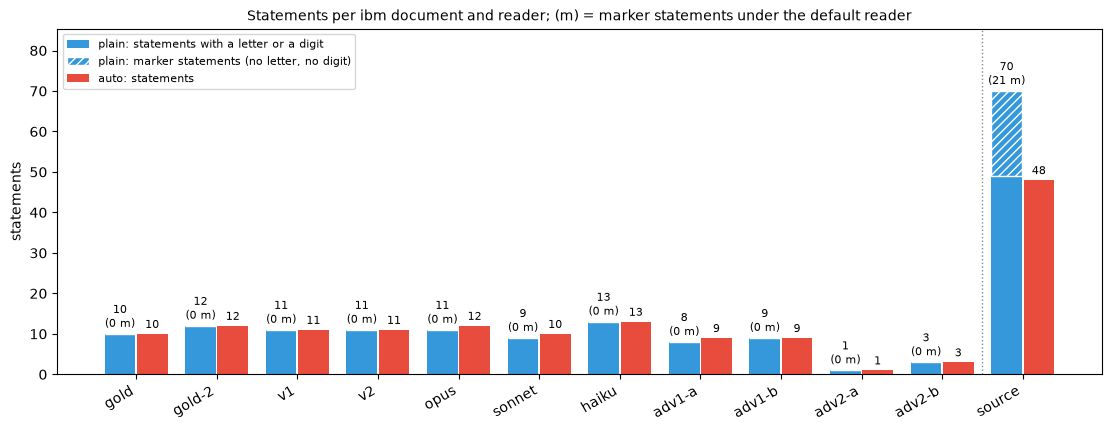

In [16]:
fig, ax = plt.subplots(figsize=(11, 4.2), constrained_layout=True)
x = np.arange(len(IBM_LABELS))
plain_n = np.array([STATEMENT_ROWS[lbl]["plain_n"] for lbl in IBM_LABELS])
plain_markers = np.array([STATEMENT_ROWS[lbl]["plain_markers"] for lbl in IBM_LABELS])
auto_n = np.array([STATEMENT_ROWS[lbl]["auto_n"] for lbl in IBM_LABELS])
ax.bar(x - 0.2, plain_n - plain_markers, 0.38, color=COL_PLAIN, label="plain: statements with a letter or a digit")
ax.bar(x - 0.2, plain_markers, 0.38, bottom=plain_n - plain_markers, color=COL_PLAIN, hatch="////", edgecolor="white",
       label="plain: marker statements (no letter, no digit)")
ax.bar(x + 0.2, auto_n, 0.38, color=COL_AUTO, label="auto: statements")
for position, lbl in enumerate(IBM_LABELS):
    ax.text(position - 0.2, plain_n[position] + 0.8, f"{plain_n[position]}\n({plain_markers[position]} m)", ha="center", va="bottom", fontsize=8)
    ax.text(position + 0.2, auto_n[position] + 0.8, f"{auto_n[position]}", ha="center", va="bottom", fontsize=8)
ax.axvline(len(LABELS) - 0.5, color=COL_REFERENCE, linestyle=":", linewidth=1)
ax.set_xticks(x, IBM_LABELS, rotation=30, ha="right")
ax.set_ylabel("statements")
ax.set_ylim(0, plain_n.max() * 1.22)
ax.set_title("Statements per ibm document and reader; (m) = marker statements under the default reader", fontsize=10)
ax.legend(fontsize=8, loc="upper left")
plt.show()

## Clause 2 - closeness to the reference, tier order and band width

The `auto` arm is scored here: the E12-H63 reading (closeness of the 10 summaries to the gold reference) and the 55
pair distances through the public call. The band of an arm runs from the highest adversarial closeness to the lowest
gold-tier closeness:

$$\mathrm{band} = \big[\max_{a \in \mathrm{adv}} \mathrm{closeness}(a),\; \min_{g \in \mathrm{gold}} \mathrm{closeness}(g)\big], \qquad \mathrm{width} = \mathrm{upper} - \mathrm{lower}$$

The clause requires that under `auto` every gold-tier summary reads above every adversarial summary and that the
`auto` band is at least as wide as the plain band of this run.

In [17]:
with contextlib.redirect_stderr(io.StringIO()):
    ARM["auto"] = reference_readings("auto")
    D55["auto"] = pair_distances("auto")

CL = {arm: ARM[arm]["closeness"] for arm in ARMS}
DELTA_CL = {lbl: CL["auto"][lbl] - CL["plain"][lbl] for lbl in SCORED}
N_LOWER = sum(delta < 0 for delta in DELTA_CL.values())
N_EQUAL_CL = sum(delta == 0 for delta in DELTA_CL.values())
N_HIGHER = sum(delta > 0 for delta in DELTA_CL.values())
TIER_ORDER_AUTO = min(CL["auto"][g] for g in GOLDS) > max(CL["auto"][a] for a in ADVS)
WIDTH_OK = ARM["auto"]["width"] >= ARM["plain"]["width"]
CLAUSE2 = bool(TIER_ORDER_AUTO and WIDTH_OK)
SHIFT = {edge: ARM["plain"][edge] - ARM["auto"][edge] for edge in ("lo", "hi", "midpoint")}     # plain minus auto: positive = auto lies lower
EDGE_DOCS = sorted({ARM[arm][key] for arm in ARMS for key in ("lo_doc", "hi_doc")} | {REFERENCE})
EDGE_DOCS_UNCHANGED = {lbl: STATEMENT_ROWS[lbl]["embedded_equal"] for lbl in EDGE_DOCS}
# the same 10 pairs among the 55 public-call distances
PAIR_INDEX = {frozenset(pair): i for i, pair in enumerate(PAIRS)}
PUBLIC_VS_SCORE = {arm: max(abs(D55[arm][PAIR_INDEX[frozenset((lbl, REFERENCE))]] - ARM[arm]["smd"][lbl]) for lbl in SCORED) for arm in ARMS}

ORDER = sorted(SCORED, key=lambda lbl: (tier_of[lbl] != "gold", -CL["plain"][lbl]))
console.print(Group(
    make_table(f"Closeness of the {len(SCORED)} summaries to the reference '{REFERENCE}' per reader",
               ["summary", "tier", "statements plain / auto", "SMD plain", "SMD auto", "closeness plain", "closeness auto", "auto - plain (points)",
                f"verdict at {DEFAULT_THRESHOLD}: plain", "verdict: auto"],
               [[lbl, tier_of[lbl], f"{STATEMENT_ROWS[lbl]['plain_n']} / {STATEMENT_ROWS[lbl]['auto_n']}", f"{ARM['plain']['smd'][lbl]:.4f}",
                 f"{ARM['auto']['smd'][lbl]:.4f}", f"{CL['plain'][lbl]:.4f}", f"{CL['auto'][lbl]:.4f}", f"{DELTA_CL[lbl] * 100:+.2f}",
                 verdict(CL["plain"][lbl]), verdict(CL["auto"][lbl])] for lbl in ORDER], left=2),
    make_table("Band between the tiers per reader",
               ["reader", "lower edge (highest adversarial)", "set by", "upper edge (lowest gold tier)", "set by", "width", "midpoint", "V"],
               [[arm, f"{ARM[arm]['lo']:.4f}", ARM[arm]["lo_doc"], f"{ARM[arm]['hi']:.4f}", ARM[arm]["hi_doc"], f"{ARM[arm]['width']:.4f}",
                 f"{ARM[arm]['midpoint']:.4f}", f"{ARM[arm]['V']}/{V_PAIRS}"] for arm in ARMS]),
    f"clause 2: every gold-tier summary above every adversarial summary under auto: {TIER_ORDER_AUTO}; auto band width {ARM['auto']['width']:.6f}"
    f" >= plain band width {ARM['plain']['width']:.6f}: {WIDTH_OK} → [bold]{'met' if CLAUSE2 else 'not met'}[/bold]\n"
    f"closeness under auto against plain: lower for {N_LOWER} of {len(SCORED)}, equal as floats for {N_EQUAL_CL}, higher for {N_HIGHER}"
    f" (the prediction names at least {PRED_LOWER_MIN} lower)\n"
    f"band position, plain minus auto: lower edge {SHIFT['lo']:+.4f}, upper edge {SHIFT['hi']:+.4f}, midpoint {SHIFT['midpoint']:+.4f}"
    f" (the prediction names {PRED_SHIFT_MIN} to {PRED_SHIFT_MAX})\n"
    f"second readings: embedded statement list equal under both readers for the documents that set an edge and the reference: {EDGE_DOCS_UNCHANGED};"
    f" largest difference between the E12-H63 score and the public call on the 10 reference pairs: plain {PUBLIC_VS_SCORE['plain']:.1e},"
    f" auto {PUBLIC_VS_SCORE['auto']:.1e}"))

                                                   Closeness of the 10 summaries to the reference 'gold' per reader                                                    
┏━━━━━━━━━┳━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ summary ┃ tier ┃ statements plain / auto ┃ SMD plain ┃ SMD auto ┃ closeness plain ┃ closeness auto ┃ auto - plain (points) ┃ verdict at 0.77: plain ┃ verdict: auto ┃
┡━━━━━━━━━╇━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ v2      │ gold │                 11 / 11 │    0.2082 │   0.2082 │          0.8528 │         0.8528 │                 +0.00 │                similar │       similar │
│ gold-2  │ gold │                 12 / 12 │    0.2265 │   0.2265 │          0.8398 │         0.8398 │                 +0.00 │                similar │       similar │
│ opus    │ gold │                 11 / 12 │    0.2366 │   0.2495 │          0.8327 │         0.8236 │                 -0.91 │                similar │       similar │
│ sonnet  │ gold │                  9 / 10 │    0.2537 │   0.2536 │          0.8206 │         0.8207 │                 +0.01 │                similar │       similar │
│ v1      │ gold │                 11 / 11 │    0.2582 │   0.2582 │          0.8174 │         0.8174 │                 +0.00 │                similar │       similar │
│ haiku   │ gold │                 13 / 13 │    0.2907 │   0.2907 │          0.7944 │         0.7944 │                 +0.00 │                similar │       similar │
│ adv2-b  │ adv2 │                   3 / 3 │    0.3573 │   0.3573 │          0.7474 │         0.7474 │                 +0.00 │            not similar │   not similar │
│ adv2-a  │ adv2 │                   1 / 1 │    0.3806 │   0.3806 │          0.7309 │         0.7309 │                 +0.00 │            not similar │   not similar │
│ adv1-b  │ adv1 │                   9 / 9 │    0.4458 │   0.4458 │          0.6847 │         0.6847 │                 +0.00 │            not similar │   not similar │
│ adv1-a  │ adv1 │                   8 / 9 │    0.4569 │   0.4758 │          0.6769 │         0.6636 │                 -1.34 │            not similar │   not similar │
└─────────┴──────┴─────────────────────────┴───────────┴──────────┴─────────────────┴────────────────┴───────────────────────┴────────────────────────┴───────────────┘
                                            Band between the tiers per reader                                             
┏━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━┳━━━━━━┓
┃ reader ┃ lower edge (highest adversarial) ┃ set by ┃ upper edge (lowest gold tier) ┃ set by ┃  width ┃ midpoint ┃    V ┃
┡━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━╇━━━━━━┩
│ plain  │                           0.7474 │ adv2-b │                        0.7944 │  haiku │ 0.0471 │   0.7709 │ 0/24 │
│ auto   │                           0.7474 │ adv2-b │                        0.7944 │  haiku │ 0.0471 │   0.7709 │ 0/24 │
└────────┴──────────────────────────────────┴────────┴───────────────────────────────┴────────┴────────┴──────────┴──────┘
clause 2: every gold-tier summary above every adversarial summary under auto: True; auto band width 0.047083 >= plain band width 0.047083: True → met
closeness under auto against plain: lower for 2 of 10, equal as floats for 7, higher for 1 (the prediction names at least 9 lower)
band position, plain minus auto: lower edge +0.0000, upper edge +0.0000, midpoint +0.0000 (the prediction names 0.01 to 0.06)
second readings: embedded statement list equal under both readers for the documents that set an edge and the reference: {'adv2-b': True, 'gold': True, 'haiku': True}; 
largest difference between the E12-H63 score

The figure shows the closeness of each summary to the reference under both readers, the band of each reader and
`DEFAULT_THRESHOLD`. The reading to check is whether any `auto` point crosses the band or the threshold relative to
its plain point.

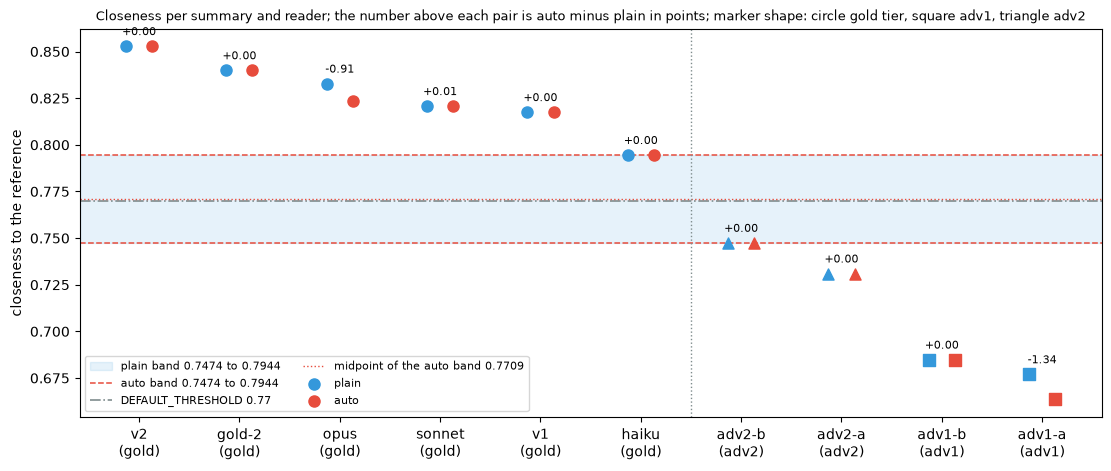

In [18]:
fig, ax = plt.subplots(figsize=(11, 4.6), constrained_layout=True)
x = np.arange(len(ORDER))
ax.axhspan(ARM["plain"]["lo"], ARM["plain"]["hi"], color=COL_PLAIN, alpha=0.12, label=f"plain band {ARM['plain']['lo']:.4f} to {ARM['plain']['hi']:.4f}")
for edge in ("lo", "hi"):
    ax.axhline(ARM["auto"][edge], color=COL_AUTO, linestyle="--", linewidth=1.1,
               label=f"auto band {ARM['auto']['lo']:.4f} to {ARM['auto']['hi']:.4f}" if edge == "lo" else None)
ax.axhline(DEFAULT_THRESHOLD, color=COL_REFERENCE, linestyle="-.", linewidth=1.2, label=f"DEFAULT_THRESHOLD {DEFAULT_THRESHOLD}")
ax.axhline(ARM["auto"]["midpoint"], color=COL_AUTO, linestyle=":", linewidth=1.0, label=f"midpoint of the auto band {ARM['auto']['midpoint']:.4f}")
for position, lbl in enumerate(ORDER):
    for arm, offset in (("plain", -0.13), ("auto", 0.13)):
        ax.scatter(position + offset, CL[arm][lbl], s=64, marker=TIER_MARKER[tier_of[lbl]], color=READER_COLOR[arm], zorder=3,
                   label=arm if position == 0 else None)
    ax.annotate(f"{DELTA_CL[lbl] * 100:+.2f}", (position, max(CL["plain"][lbl], CL["auto"][lbl]) + 0.006), ha="center", fontsize=8)
ax.axvline(len(GOLDS) - 0.5, color=COL_REFERENCE, linestyle=":", linewidth=1)
ax.set_xticks(x, [f"{lbl}\n({tier_of[lbl]})" for lbl in ORDER])
ax.set_ylabel("closeness to the reference")
ax.set_title("Closeness per summary and reader; the number above each pair is auto minus plain in points;"
             " marker shape: circle gold tier, square adv1, triangle adv2", fontsize=9)
ax.legend(fontsize=8, loc="lower left", ncol=2)
plt.show()

## Clause 3 - the 55 pair distances under both readers

The 55 pair distances of each arm come from `DocDistance.semantic_distance` on the same instance. The clause requires
a Spearman correlation of at least `0.90` between the two readers. Because a pair of two summaries whose statement
lists are equal under both readers reads the same distance, the number of pairs with an equal distance and the
correlation over the pairs that differ are printed beside the clause reading.

In [19]:
SPEARMAN = float(spearmanr(D55["plain"], D55["auto"]).statistic)
CLAUSE3 = SPEARMAN >= SPEARMAN_BAR
PAIR_DIFF = D55["auto"] - D55["plain"]
DIFFERS = D55["auto"] != D55["plain"]
N_PAIRS_EQUAL = int((~DIFFERS).sum())
N_PAIRS_DIFFER = int(DIFFERS.sum())
SPEARMAN_DIFFERING = float(spearmanr(D55["plain"][DIFFERS], D55["auto"][DIFFERS]).statistic) if N_PAIRS_DIFFER > 2 else None
PAIR_TOUCHES_DIFFERING = np.array([a in DIFFERING_SUMMARIES or b in DIFFERING_SUMMARIES for a, b in PAIRS])
DIFFERS_IFF_TOUCHES = bool(np.array_equal(DIFFERS, PAIR_TOUCHES_DIFFERING))
MAX_ABS_PAIR_DIFF = float(np.abs(PAIR_DIFF).max())
MAX_PAIR = PAIRS[int(np.abs(PAIR_DIFF).argmax())]

console.print(Group(
    make_table(f"The {len(PAIRS)} pair distances per reader (SMD, order of baseline.py)",
               ["#", "document A", "document B", "plain", "auto", "auto - plain"],
               [[i + 1, a, b, f"{D55['plain'][i]:.6f}", f"{D55['auto'][i]:.6f}", f"{PAIR_DIFF[i]:+.6f}"] for i, (a, b) in enumerate(PAIRS)], left=3),
    f"clause 3: Spearman of the {len(PAIRS)} pair distances between plain and auto {SPEARMAN:.4f} (bar >= {SPEARMAN_BAR})"
    f" → [bold]{'met' if CLAUSE3 else 'not met'}[/bold]\n"
    f"second readings: {N_PAIRS_EQUAL} of {len(PAIRS)} pairs read the same float under both readers; Spearman over the {N_PAIRS_DIFFER} pairs that differ"
    f" {fmt4(SPEARMAN_DIFFERING)}; a pair differs exactly when it holds one of {DIFFERING_SUMMARIES}: {DIFFERS_IFF_TOUCHES};"
    f" largest absolute difference {MAX_ABS_PAIR_DIFF:.4f} on {MAX_PAIR}"))

    The 55 pair distances per reader (SMD, order of baseline.py)     
┏━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ #  ┃ document A ┃ document B ┃    plain ┃     auto ┃ auto - plain ┃
┡━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ 1  │ v1         │ v2         │ 0.242371 │ 0.242371 │    +0.000000 │
│ 2  │ v1         │ adv1-a     │ 0.443739 │ 0.468359 │    +0.024620 │
│ 3  │ v1         │ adv1-b     │ 0.439748 │ 0.439748 │    +0.000000 │
│ 4  │ v1         │ adv2-a     │ 0.391953 │ 0.391953 │    +0.000000 │
│ 5  │ v1         │ adv2-b     │ 0.363271 │ 0.363271 │    +0.000000 │
│ 6  │ v1         │ gold-2     │ 0.248008 │ 0.248008 │    +0.000000 │
│ 7  │ v1         │ gold       │ 0.258200 │ 0.258200 │    +0.000000 │
│ 8  │ v1         │ haiku      │ 0.304229 │ 0.304229 │    +0.000000 │
│ 9  │ v1         │ opus       │ 0.256856 │ 0.274405 │    +0.017549 │
│ 10 │ v1         │ sonnet     │ 0.271389 │ 0.271961 │    +0.000573 │
│ 11 │ v2         │ adv1-a     │ 0.449933 │ 0.474252 │    +0.024319 │
│ 12 │ v2         │ adv1-b     │ 0.440065 │ 0.440065 │    +0.000000 │
│ 13 │ v2         │ adv2-a     │ 0.380864 │ 0.380864 │    +0.000000 │
│ 14 │ v2         │ adv2-b     │ 0.353289 │ 0.353289 │    +0.000000 │
│ 15 │ v2         │ gold-2     │ 0.210002 │ 0.210002 │    +0.000000 │
│ 16 │ v2         │ gold       │ 0.208169 │ 0.208169 │    +0.000000 │
│ 17 │ v2         │ haiku      │ 0.259686 │ 0.259686 │    +0.000000 │
│ 18 │ v2         │ opus       │ 0.240088 │ 0.262661 │    +0.022573 │
│ 19 │ v2         │ sonnet     │ 0.259205 │ 0.261982 │    +0.002777 │
│ 20 │ adv1-a     │ adv1-b     │ 0.231453 │ 0.263576 │    +0.032123 │
│ 21 │ adv1-a     │ adv2-a     │ 0.422183 │ 0.454215 │    +0.032033 │
│ 22 │ adv1-a     │ adv2-b     │ 0.439155 │ 0.471382 │    +0.032227 │
│ 23 │ adv1-a     │ gold-2     │ 0.447724 │ 0.468448 │    +0.020725 │
│ 24 │ adv1-a     │ gold       │ 0.456903 │ 0.475791 │    +0.018888 │
│ 25 │ adv1-a     │ haiku      │ 0.447335 │ 0.467184 │    +0.019849 │
│ 26 │ adv1-a     │ opus       │ 0.449253 │ 0.465389 │    +0.016136 │
│ 27 │ adv1-a     │ sonnet     │ 0.444743 │ 0.458412 │    +0.013670 │
│ 28 │ adv1-b     │ adv2-a     │ 0.417604 │ 0.417604 │    +0.000000 │
│ 29 │ adv1-b     │ adv2-b     │ 0.434557 │ 0.434557 │    +0.000000 │
│ 30 │ adv1-b     │ gold-2     │ 0.439304 │ 0.439304 │    +0.000000 │
│ 31 │ adv1-b     │ gold       │ 0.445837 │ 0.445837 │    +0.000000 │
│ 32 │ adv1-b     │ haiku      │ 0.443224 │ 0.443224 │    +0.000000 │
│ 33 │ adv1-b     │ opus       │ 0.436852 │ 0.437184 │    +0.000332 │
│ 34 │ adv1-b     │ sonnet     │ 0.437873 │ 0.434350 │    -0.003523 │
│ 35 │ adv2-a     │ adv2-b     │ 0.222017 │ 0.222017 │    +0.000000 │
│ 36 │ adv2-a     │ gold-2     │ 0.381963 │ 0.381963 │    +0.000000 │
│ 37 │ adv2-a     │ gold       │ 0.380551 │ 0.380551 │    +0.000000 │
│ 38 │ adv2-a     │ haiku      │ 0.386642 │ 0.386642 │    +0.000000 │
│ 39 │ adv2-a     │ opus       │ 0.378762 │ 0.389696 │    +0.010934 │
│ 40 │ adv2-a     │ sonnet     │ 0.358159 │ 0.362934 │    +0.004775 │
│ 41 │ adv2-b     │ gold-2     │ 0.358283 │ 0.358283 │    +0.000000 │
│ 42 │ adv2-b     │ gold       │ 0.357292 │ 0.357292 │    +0.000000 │
│ 43 │ adv2-b     │ haiku      │ 0.367749 │ 0.367749 │    +0.000000 │
│ 44 │ adv2-b     │ opus       │ 0.360480 │ 0.373109 │    +0.012629 │
│ 45 │ adv2-b     │ sonnet     │ 0.335749 │ 0.343718 │    +0.007969 │
│ 46 │ gold-2     │ gold       │ 0.226490 │ 0.226490 │    +0.000000 │
│ 47 │ gold-2     │ haiku      │ 0.264238 │ 0.264238 │    +0.000000 │
│ 48 │ gold-2     │ opus       │ 0.256040 │ 0.258740 │    +0.002700 │
│ 49 │ gold-2     │ sonnet     │ 0.245215 │ 0.249644 │    +0.004429 │
│ 50 │ gold       │ haiku      │ 0.290706 │ 0.290706 │    +0.000000 │
│ 51 │ gold       │ opus       │ 0.236586 │ 0.249523 │    +0.012937 │
│ 52 │ gold       │ sonnet     │ 0.253713 │ 0.253609 │    -0.000104 │
│ 53 │ haiku      │ opus       │ 0.296923 │ 0.301374 │    +0.004451 │
│ 54 │ hai

The figure plots the distance of each pair under `auto` against its distance under the default reader. The reading to
check is how far the pairs that differ lie from the diagonal, which is where every pair with an equal distance lies.

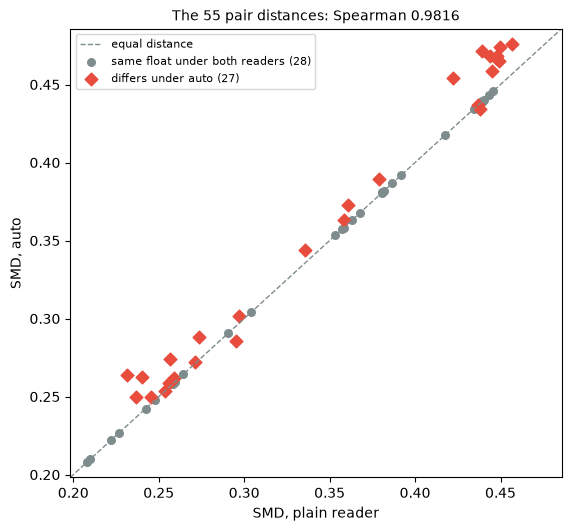

In [20]:
fig, ax = plt.subplots(figsize=(5.6, 5.2), constrained_layout=True)
low, high = min(D55["plain"].min(), D55["auto"].min()) - 0.01, max(D55["plain"].max(), D55["auto"].max()) + 0.01
ax.plot([low, high], [low, high], color=COL_REFERENCE, linestyle="--", linewidth=1, label="equal distance")
ax.scatter(D55["plain"][~DIFFERS], D55["auto"][~DIFFERS], s=30, marker="o", color=COL_REFERENCE,
           label=f"same float under both readers ({N_PAIRS_EQUAL})")
ax.scatter(D55["plain"][DIFFERS], D55["auto"][DIFFERS], s=42, marker="D", color=COL_AUTO,
           label=f"differs under auto ({N_PAIRS_DIFFER})")
ax.set_xlim(low, high)
ax.set_ylim(low, high)
ax.set_xlabel("SMD, plain reader")
ax.set_ylabel("SMD, auto")
ax.set_title(f"The {len(PAIRS)} pair distances: Spearman {SPEARMAN:.4f}", fontsize=10)
ax.legend(fontsize=8, loc="upper left")
plt.show()

## Clause 4 - HTML render against markdown original

For each of the 12 ibm documents the embedded statement list of the HTML render under `auto` is compared, string for
string, with the list of the markdown original under `auto`. Both lists come from `segmented_lists`; the cell also
checks that the text `_read_as` returns for a render is `html_to_markdown` of the file with the title lines removed.
The SMD between the two files is read through the public call `semantic_distance(original, render,
input_format="auto")`. The clause requires equal lists and an SMD of at most `0.001` for all 12. For an unequal
pair the second table lists every differing statement with the ground cost between its two versions.

In [21]:
TWIN, TWIN_DIFFERENCES = {}, []
with contextlib.redirect_stderr(io.StringIO()):
    for lbl in IBM_LABELS:
        original, render = READ[("original", lbl, "auto")], READ[("render", lbl, "auto")]
        render_path = FILES[("render", lbl)]
        converted = pipeline._strip_titles(html_to_markdown(render_path.read_text(encoding="utf-8")))
        differing = [i for i, (a, b) in enumerate(zip(original["embedded"], render["embedded"])) if a != b]
        TWIN[lbl] = {"reader_original": original["reader"], "reader_render": render["reader"],
                     "conversion_equals_read_as": converted == _read_as(render_path, "auto")[0],
                     "n_original": len(original["embedded"]), "n_render": len(render["embedded"]),
                     "lists_equal": original["embedded"] == render["embedded"], "n_differing": len(differing),
                     "smd": float(dd.semantic_distance(ORIGINAL[lbl], render_path, input_format="auto").smd)}
        TWIN[lbl]["smd_ok"] = TWIN[lbl]["smd"] <= TWIN_SMD_BAR
        if len(original["embedded"]) == len(render["embedded"]):
            TWIN_DIFFERENCES += [{"document": lbl, "index": i, "original": original["embedded"][i], "render": render["embedded"][i],
                                  "ground_cost": float(np.linalg.norm(original["emb"][i].astype(np.float64) - render["emb"][i].astype(np.float64)))}
                                 for i in differing]

N_TWIN_EQUAL = sum(row["lists_equal"] for row in TWIN.values())
N_TWIN_SMD_OK = sum(row["smd_ok"] for row in TWIN.values())
N_CONVERSION_EQUAL = sum(row["conversion_equals_read_as"] for row in TWIN.values())
CLAUSE4 = N_TWIN_EQUAL == len(IBM_LABELS) and N_TWIN_SMD_OK == len(IBM_LABELS)
TWIN_MAX_SMD = max(row["smd"] for row in TWIN.values())
TWIN_MAX_DOC = max(TWIN, key=lambda lbl: TWIN[lbl]["smd"])
TWIN_MAX_SMD_EQUAL_LISTS = max(row["smd"] for row in TWIN.values() if row["lists_equal"])

console.print(Group(
    make_table("Clause 4 - embedded statements of the HTML render against the markdown original, both under auto",
               ["document", "reader: original", "reader: render", "statements: original", "statements: render", "lists equal string for string",
                "differing statements", "SMD(original, render)", f"SMD <= {TWIN_SMD_BAR}"],
               [[lbl, row["reader_original"], row["reader_render"], row["n_original"], row["n_render"], yes_no(row["lists_equal"]), row["n_differing"],
                 f"{row['smd']:.3e}", yes_no(row["smd_ok"])] for lbl, row in TWIN.items()]),
    make_table("Differing statements of the unequal pairs", ["document", "index", "embedded text, markdown original", "embedded text, HTML render", "ground cost"],
               [[d["document"], d["index"], d["original"][:80], d["render"][:80], f"{d['ground_cost']:.4f}"] for d in TWIN_DIFFERENCES]
               or [["none", "-", "-", "-", "-"]], left=4),
    f"clause 4: lists equal for {N_TWIN_EQUAL} of {len(IBM_LABELS)} documents, SMD <= {TWIN_SMD_BAR} for {N_TWIN_SMD_OK} of {len(IBM_LABELS)}"
    f" → [bold]{'met' if CLAUSE4 else 'not met'}[/bold]\n"
    f"second readings: largest SMD {TWIN_MAX_SMD:.3e} ({TWIN_MAX_DOC}); largest SMD among the pairs with equal lists {TWIN_MAX_SMD_EQUAL_LISTS:.3e};"
    f" the text _read_as returns for a render equals html_to_markdown of the file with the title lines removed for {N_CONVERSION_EQUAL} of {len(IBM_LABELS)}"))

                                     Clause 4 - embedded statements of the HTML render against the markdown original, both under auto                                     
┏━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃          ┃                  ┃                ┃        statements: ┃                    ┃  lists equal string ┃          differing ┃       SMD(original, ┃              ┃
┃ document ┃ reader: original ┃ reader: render ┃           original ┃ statements: render ┃          for string ┃         statements ┃             render) ┃ SMD <= 0.001 ┃
┡━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ gold     │         markdown │           html │                 10 │                 10 │                 yes │                  0 │           1.869e-04 │          yes │
│ gold-2   │         markdown │           html │                 12 │                 12 │                 yes │                  0 │           2.203e-04 │          yes │
│ v1       │         markdown │           html │                 11 │                 11 │                 yes │                  0 │           3.575e-04 │          yes │
│ v2       │         markdown │           html │                 11 │                 11 │                 yes │                  0 │           1.829e-04 │          yes │
│ opus     │         markdown │           html │                 12 │                 12 │                 yes │                  0 │           1.806e-04 │          yes │
│ sonnet   │         markdown │           html │                 10 │                 10 │                 yes │                  0 │           1.953e-04 │          yes │
│ haiku    │         markdown │           html │                 13 │                 13 │                 yes │                  0 │           2.563e-04 │          yes │
│ adv1-a   │         markdown │           html │                  9 │                  9 │                 yes │                  0 │           1.310e-04 │          yes │
│ adv1-b   │         markdown │           html │                  9 │                  9 │                 yes │                  0 │           3.836e-05 │          yes │
│ adv2-a   │         markdown │           html │                  1 │                  1 │                 yes │                  0 │           0.000e+00 │          yes │
│ adv2-b   │         markdown │           html │                  3 │                  3 │                 yes │                  0 │           1.628e-04 │          yes │
│ source   │         markdown │           html │                 48 │                 48 │                  no │                  1 │           2.856e-03 │           no │
└──────────┴──────────────────┴────────────────┴────────────────────┴────────────────────┴─────────────────────┴────────────────────┴─────────────────────┴──────────────┘
                                                       Differing statements of the unequal pairs                                                        
┏━━━━━━━━━━┳━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃ document ┃ index ┃ embedded text, markdown original                          ┃ embedded text, HTML render                              ┃ ground cost ┃
┡━━━━━━━━━━╇━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ source   │ 0     │ *IBM Newsroom - ARMONK, N.Y., Jan. 10, 2024 (PRNewswire)* │ IBM Newsroom - ARMONK, N.Y., Jan. 10, 2024 (PRNewswire) │      0.1280 │
└──────────┴───────┴───────────────────────────────────────────────────────────┴─────────────────────────────────────────────────────────┴─────────────┘
clau

The figure shows the SMD between each HTML render and its markdown original under `auto`, against the registered
ceiling of `0.001`. A hatched bar marks a pair whose embedded statement lists are not equal.

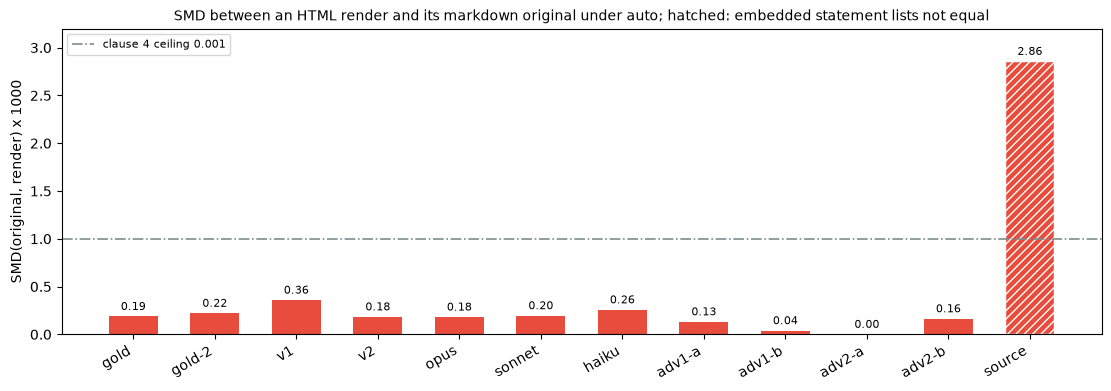

In [22]:
fig, ax = plt.subplots(figsize=(11, 3.8), constrained_layout=True)
x = np.arange(len(IBM_LABELS))
twin_smd = np.array([TWIN[lbl]["smd"] for lbl in IBM_LABELS])
bars = ax.bar(x, twin_smd * 1e3, 0.6, color=COL_AUTO)
for bar, lbl in zip(bars, IBM_LABELS):
    if not TWIN[lbl]["lists_equal"]:
        bar.set_hatch("////")
        bar.set_edgecolor("white")
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.04, f"{TWIN[lbl]['smd'] * 1e3:.2f}", ha="center", va="bottom", fontsize=8)
ax.axhline(TWIN_SMD_BAR * 1e3, color=COL_REFERENCE, linestyle="-.", linewidth=1.2, label=f"clause 4 ceiling {TWIN_SMD_BAR}")
ax.set_xticks(x, IBM_LABELS, rotation=30, ha="right")
ax.set_ylim(0, twin_smd.max() * 1e3 * 1.12)
ax.set_ylabel("SMD(original, render) x 1000")
ax.set_title("SMD between an HTML render and its markdown original under auto; hatched: embedded statement lists not equal", fontsize=10)
ax.legend(fontsize=8, loc="upper left")
plt.show()

## Readings without a bar

The four readings the record asks for without a bar. None of them enters the bar or the verdict.

- **`DEFAULT_THRESHOLD` against the band** - a threshold separates the two tiers when `lower edge < threshold <= upper edge`; the margins to both edges and the midpoint are printed per reader
- **Wergeland article** - a band needs a gold tier and an adversarial tier of documents that hold markup; the cell counts what the fixtures hold for that article
- **`n_unsupported`** - `unsupported_count(summary, ibm source)` for the 7 gold-tier summaries per reader
- **`match_status` counts** - `n_kept` / `n_removed` / `n_added` of the shipped semantic detail file, each gold-tier summary against the ibm source, and the gold reference against each of the 6 other gold-tier summaries

In [23]:
def threshold_reading(arm: str) -> dict:
    """Where ``DEFAULT_THRESHOLD`` lies against the band of one arm."""
    lo, hi = ARM[arm]["lo"], ARM[arm]["hi"]
    return {"inside": bool(lo < DEFAULT_THRESHOLD <= hi), "above_lower_edge": DEFAULT_THRESHOLD - lo, "below_upper_edge": hi - DEFAULT_THRESHOLD,
            "midpoint": ARM[arm]["midpoint"], "threshold_minus_midpoint": DEFAULT_THRESHOLD - ARM[arm]["midpoint"]}


def match_counts(path_a: Path, path_b: Path, requested: str) -> dict:
    """``n_kept`` / ``n_removed`` / ``n_added`` of the shipped semantic detail file for one pair under one reader."""
    summary = dd.semantic_distance_with_details(path_a, path_b, **seg_kwargs(requested))[1]["summary"]
    return {"kept": summary["n_kept"], "removed": summary["n_removed"], "added": summary["n_added"]}


THRESHOLD = {arm: threshold_reading(arm) for arm in ARMS}
VERDICTS = {arm: {lbl: verdict(CL[arm][lbl]) for lbl in SCORED} for arm in ARMS}
N_VERDICT_FLIPS = sum(VERDICTS["plain"][lbl] != VERDICTS["auto"][lbl] for lbl in SCORED)

# Wergeland: what the fixtures hold for a band
structure = json.loads(STRUCTURE_STATEMENTS.read_text(encoding="utf-8"))
WERG_STORED = {key: doc for key, doc in structure.items() if doc.get("article") == "wergeland"}
WERG_STORED_TIERS = dict(Counter(doc["tier"] for doc in WERG_STORED.values()))
WERG_STORED_KINDS = dict(Counter(doc["kind"] for doc in WERG_STORED.values()))
WERG_N_ADVERSARIAL = sum(doc["tier"] != "gold" for doc in WERG_STORED.values())
WERG_STORED_MARKERS = sum(is_marker(s) for doc in WERG_STORED.values() for s in doc["statements"])
WERG_BAND_MEASURABLE = WERG_N_ADVERSARIAL > 0

with contextlib.redirect_stderr(io.StringIO()):
    SOURCE_EMB = {arm: READ[("original", "source", arm)]["emb"] for arm in ARMS}
    UNSUPPORTED = {lbl: {arm: unsupported_count(READ[("original", lbl, arm)]["emb"], SOURCE_EMB[arm]) for arm in ARMS} for lbl in GOLD_TIER}
    MATCH_SOURCE = {lbl: {arm: match_counts(ORIGINAL[lbl], IBM_SOURCE, arm) for arm in ARMS} for lbl in GOLD_TIER}
    MATCH_REFERENCE = {lbl: {arm: match_counts(ORIGINAL[REFERENCE], ORIGINAL[lbl], arm) for arm in ARMS} for lbl in GOLD_TIER if lbl != REFERENCE}
UNSUPPORTED_TOTAL = {arm: sum(UNSUPPORTED[lbl][arm] for lbl in GOLD_TIER) for arm in ARMS}
GOLD_TIER_STATEMENTS = {arm: sum(READ[("original", lbl, arm)]["n"] for lbl in GOLD_TIER) for arm in ARMS}
MATCH_SOURCE_TOTAL = {arm: {field: sum(MATCH_SOURCE[lbl][arm][field] for lbl in GOLD_TIER) for field in ("kept", "removed", "added")} for arm in ARMS}
MATCH_REFERENCE_TOTAL = {arm: {field: sum(row[arm][field] for row in MATCH_REFERENCE.values()) for field in ("kept", "removed", "added")} for arm in ARMS}


def counts_text(counts: dict) -> str:
    """``kept / removed / added`` of one match-count record."""
    return f"{counts['kept']} / {counts['removed']} / {counts['added']}"


console.print(Group(
    make_table(f"DEFAULT_THRESHOLD {DEFAULT_THRESHOLD} against the band of each reader",
               ["reader", "lower edge", "upper edge", "lower edge < threshold <= upper edge", "threshold - lower edge", "upper edge - threshold",
                "midpoint", "threshold - midpoint"],
               [[arm, f"{ARM[arm]['lo']:.4f}", f"{ARM[arm]['hi']:.4f}", yes_no(THRESHOLD[arm]["inside"]), f"{THRESHOLD[arm]['above_lower_edge']:.4f}",
                 f"{THRESHOLD[arm]['below_upper_edge']:.4f}", f"{THRESHOLD[arm]['midpoint']:.4f}", f"{THRESHOLD[arm]['threshold_minus_midpoint']:+.4f}"]
                for arm in ARMS]),
    f"summaries whose verdict at {DEFAULT_THRESHOLD} differs between the readers: {N_VERDICT_FLIPS} of {len(SCORED)}",
    make_table("Wergeland article - what the fixtures hold for a band", ["reading", "value"],
               [["document files under ai-society-wergeland/source", WERG_NAMES],
                ["stored Wergeland documents in structure-fixture/statements.json (statement lists, no file)", sorted(WERG_STORED)],
                ["their tiers", WERG_STORED_TIERS], ["their kinds", WERG_STORED_KINDS],
                ["adversarial-tier Wergeland documents", WERG_N_ADVERSARIAL],
                ["marker statements in the stored Wergeland statement lists", WERG_STORED_MARKERS],
                ["a band between two tiers can be read", yes_no(WERG_BAND_MEASURABLE)]]),
    make_table("n_unsupported of the 7 gold-tier summaries against the ibm source per reader"
               f" (nearest-source cost above {SOURCE_SUPPORT_CUTOFF}; source statements plain {len(SOURCE_EMB['plain'])}, auto {len(SOURCE_EMB['auto'])})",
               ["summary", "statements plain / auto", "n_unsupported plain", "n_unsupported auto"],
               [[lbl, f"{READ[('original', lbl, 'plain')]['n']} / {READ[('original', lbl, 'auto')]['n']}", UNSUPPORTED[lbl]["plain"], UNSUPPORTED[lbl]["auto"]]
                for lbl in GOLD_TIER]
               + [["all 7", f"{GOLD_TIER_STATEMENTS['plain']} / {GOLD_TIER_STATEMENTS['auto']}", UNSUPPORTED_TOTAL["plain"], UNSUPPORTED_TOTAL["auto"]]]),
    make_table(f"match_status counts, kept / removed / added (match cutoff {MATCH_CUTOFF})",
               ["summary", "A = summary, B = ibm source: plain", "A = summary, B = ibm source: auto", "A = reference, B = summary: plain",
                "A = reference, B = summary: auto"],
               [[lbl, counts_text(MATCH_SOURCE[lbl]["plain"]), counts_text(MATCH_SOURCE[lbl]["auto"]),
                 counts_text(MATCH_REFERENCE[lbl]["plain"]) if lbl in MATCH_REFERENCE else "-",
                 counts_text(MATCH_REFERENCE[lbl]["auto"]) if lbl in MATCH_REFERENCE else "-"] for lbl in GOLD_TIER]
               + [["all", counts_text(MATCH_SOURCE_TOTAL["plain"]), counts_text(MATCH_SOURCE_TOTAL["auto"]),
                   counts_text(MATCH_REFERENCE_TOTAL["plain"]), counts_text(MATCH_REFERENCE_TOTAL["auto"])]])))

                                                    DEFAULT_THRESHOLD 0.77 against the band of each reader                                                     
┏━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┓
┃ reader ┃ lower edge ┃ upper edge ┃ lower edge < threshold <= upper edge ┃ threshold - lower edge ┃ upper edge - threshold ┃ midpoint ┃ threshold - midpoint ┃
┡━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━┩
│ plain  │     0.7474 │     0.7944 │                                  yes │                 0.0226 │                 0.0244 │   0.7709 │              -0.0009 │
│ auto   │     0.7474 │     0.7944 │                                  yes │                 0.0226 │                 0.0244 │   0.7709 │              -0.0009 │
└────────┴────────────┴────────────┴──────────────────────────────────────┴────────────────────────┴────────────────────────┴──────────┴──────────────────────┘
summaries whose verdict at 0.77 differs between the readers: 0 of 10
                                                        Wergeland article - what the fixtures hold for a band                                                         
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ reading                                                                                    ┃                                                                 value ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ document files under ai-society-wergeland/source                                           │                              ['raw-extract.txt', 'source-article.md'] │
│ stored Wergeland documents in structure-fixture/statements.json (statement lists, no file) │ ['werg-a', 'werg-a~bt', 'werg-b', 'werg-b~bt', 'werg-c', 'werg-c~bt'] │
│ their tiers                                                                                │                                                           {'gold': 6} │
│ their kinds                                                                                │                                       {'summary': 3, 'paraphrase': 3} │
│ adversarial-tier Wergeland documents                                                       │                                                                     0 │
│ marker statements in the stored Wergeland statement lists                                  │                                                                     0 │
│ a band between two tiers can be read                                                       │                                                                    no │
└────────────────────────────────────────────────────────────────────────────────────────────┴───────────────────────────────────────────────────────────────────────┘
  n_unsupported of the 7 gold-tier summaries against the ibm source per reader  
    (nearest-source cost above 0.34625; source statements plain 70, auto 48)    
┏━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┓
┃ summary ┃ statements plain / auto ┃ n_unsupported plain ┃ n_unsupported auto ┃
┡━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━┩
│ gold    │                 10 / 10 │                   1 │                  1 │
│ gold-2  │                 12 / 12 │                   0 │                  0 │
│ v1      │                 11 / 11 │                   1 │                  1 │
│ v2      │                 11 / 11 │                   1 │                  1 │
│ opus    │                 11 / 12 │                   2 │                  3

## Outside the record - the one fixture pair in which both documents hold marker statements

An executor reading, with no registered bar and no part in the verdict. The registered mechanism needs two documents
that both hold marker statements under the default reader. Among the fixture files of this run that is one pair: the
ibm source article against the Wergeland source article, two different articles. The cell reads the SMD of that pair
under both readers and splits the transport plan of each arm by the kind of statement at both ends of an arc.

In [24]:
WERG_SOURCE = "source-article.md"
assert ("wergeland", WERG_SOURCE) in TWO_DOCUMENT_AUTO, (
    f"wergeland:{WERG_SOURCE} is passed to a two-document call under auto and is not in TWO_DOCUMENT_AUTO, the set the reader guard covers")
ARC_KINDS = ("marker → marker", "marker → content", "content → marker", "content → content")


def arc_split(arm: str) -> dict:
    """SMD of (ibm source, Wergeland source) under one arm and its transport mass and cost per kind of arc."""
    a, b = READ[("original", "source", arm)], READ[("wergeland", WERG_SOURCE, arm)]
    plan, cost = transport_plan(a["emb"], b["emb"]), cost_matrix(a["emb"], b["emb"])
    marker_a = np.array([is_marker(s) for s in a["embedded"]])
    marker_b = np.array([is_marker(s) for s in b["embedded"]])
    cells = {"marker → marker": np.ix_(marker_a, marker_b), "marker → content": np.ix_(marker_a, ~marker_b),
             "content → marker": np.ix_(~marker_a, marker_b), "content → content": np.ix_(~marker_a, ~marker_b)}
    mass = {kind: float(plan[cell].sum()) for kind, cell in cells.items()}
    part = {kind: float((plan * cost)[cell].sum()) for kind, cell in cells.items()}
    return {"smd": float(dd.semantic_distance(IBM_SOURCE, FILES[("wergeland", WERG_SOURCE)], **seg_kwargs(arm)).smd),
            "statements": (a["n"], b["n"]), "markers": (int(marker_a.sum()), int(marker_b.sum())),
            "marker_strings": [dict(Counter(s for s in doc["embedded"] if is_marker(s)).most_common()) for doc in (a, b)],
            "mass": mass, "cost_part": part,
            "mean_cost": {kind: part[kind] / mass[kind] if mass[kind] > 0 else None for kind in ARC_KINDS}}


with contextlib.redirect_stderr(io.StringIO()):
    OUTSIDE = {arm: arc_split(arm) for arm in ARMS}

console.print(Group(
    make_table("Outside the record - SMD(ibm source, Wergeland source) per reader",
               ["reader", "statements ibm / Wergeland", "marker statements ibm / Wergeland", "SMD", "closeness"],
               [[arm, f"{OUTSIDE[arm]['statements'][0]} / {OUTSIDE[arm]['statements'][1]}", f"{OUTSIDE[arm]['markers'][0]} / {OUTSIDE[arm]['markers'][1]}",
                 f"{OUTSIDE[arm]['smd']:.4f}", f"{closeness(OUTSIDE[arm]['smd']):.4f}"] for arm in ARMS]),
    make_table("Transport plan of that pair by kind of arc (ibm statement → Wergeland statement)",
               ["reader", "kind of arc", "mass", "mean ground cost", "part of the SMD"],
               [[arm, kind, f"{OUTSIDE[arm]['mass'][kind]:.4f}", "-" if OUTSIDE[arm]["mean_cost"][kind] is None else f"{OUTSIDE[arm]['mean_cost'][kind]:.4f}",
                 f"{OUTSIDE[arm]['cost_part'][kind]:.4f}"] for arm in ARMS for kind in ARC_KINDS], left=2),
    f"marker statements under plain: ibm source {OUTSIDE['plain']['marker_strings'][0]}, Wergeland source {OUTSIDE['plain']['marker_strings'][1]}\n"
    f"SMD under plain minus SMD under auto: {OUTSIDE['plain']['smd'] - OUTSIDE['auto']['smd']:+.4f}\n"
    "[dim]no bar is registered for this reading; it is one pair of two different articles[/dim]"))

               Outside the record - SMD(ibm source, Wergeland source) per reader                
┏━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━┓
┃ reader ┃ statements ibm / Wergeland ┃ marker statements ibm / Wergeland ┃    SMD ┃ closeness ┃
┡━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━┩
│ plain  │                    70 / 52 │                            21 / 3 │ 0.6416 │    0.5463 │
│ auto   │                    48 / 51 │                             0 / 0 │ 0.5255 │    0.6284 │
└────────┴────────────────────────────┴───────────────────────────────────┴────────┴───────────┘
   Transport plan of that pair by kind of arc (ibm statement → Wergeland    
                                 statement)                                 
┏━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ reader ┃ kind of arc       ┃   mass ┃ mean ground cost ┃ part of the SMD ┃
┡━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ plain  │ marker → marker   │ 0.0577 │           0.2229 │          0.0129 │
│ plain  │ marker → content  │ 0.2423 │           1.0758 │          0.2607 │
│ plain  │ content → marker  │ 0.0000 │                - │          0.0000 │
│ plain  │ content → content │ 0.7000 │           0.5258 │          0.3681 │
│ auto   │ marker → marker   │ 0.0000 │                - │          0.0000 │
│ auto   │ marker → content  │ 0.0000 │                - │          0.0000 │
│ auto   │ content → marker  │ 0.0000 │                - │          0.0000 │
│ auto   │ content → content │ 1.0000 │           0.5255 │          0.5255 │
└────────┴───────────────────┴────────┴──────────────────┴─────────────────┘
marker statements under plain: ibm source {'-': 13, '###': 6, '##': 2}, Wergeland source {'##': 2, '-->': 1}
SMD under plain minus SMD under auto: +0.1161
no bar is registered for this reading; it is one pair of two different articles

## Guardrails and clause 5

The standing guardrails, measured, together with clause 5 of the bar. Clause 5 and the default-path guardrail are the
same reading: the 55 pair distances of the plain arm against the stored 1.1.5 baseline by `np.array_equal`. `V` is
counted per reader with the E12-H63 function. The metric property is read on the 11 summaries per reader: the triangle
inequality over every unordered triple (three inequalities each, no tolerance), symmetry as the largest difference
between the two orientations of a pair, and the distance of a document to itself through the public call. The source
tree is hashed again and compared with the opening digest.

In [25]:
def distance_matrix(distances: np.ndarray) -> np.ndarray:
    """The symmetric 11 x 11 matrix of one arm from its 55 pair distances; the diagonal is 0."""
    matrix = np.zeros((len(LABELS), len(LABELS)))
    for (a, b), d in zip(PAIRS, distances):
        matrix[LABELS.index(a), LABELS.index(b)] = matrix[LABELS.index(b), LABELS.index(a)] = d
    return matrix


def triangle_reading(matrix: np.ndarray) -> dict:
    """Triangle inequality ``d(i, j) <= d(i, k) + d(k, j)`` over every unordered triple, three inequalities each."""
    slacks = [matrix[i, k] + matrix[k, j] - matrix[i, j]
              for a, b, c in itertools.combinations(range(len(matrix)), 3) for i, j, k in ((a, b, c), (a, c, b), (b, c, a))]
    return {"checks": len(slacks), "violations": int(sum(slack < 0 for slack in slacks)), "min_slack": float(min(slacks))}


CLAUSE5 = bool(np.array_equal(D55["plain"], STORED))
with contextlib.redirect_stderr(io.StringIO()):
    REVERSED = {arm: np.array([dd.semantic_distance(ORIGINAL[b], ORIGINAL[a], **seg_kwargs(arm)).smd for a, b in PAIRS]) for arm in ARMS}
    IDENTITY = {arm: max(float(dd.semantic_distance(ORIGINAL[lbl], ORIGINAL[lbl], **seg_kwargs(arm)).smd) for lbl in LABELS) for arm in ARMS}
TRIANGLE = {arm: triangle_reading(distance_matrix(D55[arm])) for arm in ARMS}
SYMMETRY = {arm: float(np.abs(REVERSED[arm] - D55[arm]).max()) for arm in ARMS}
V_OK = ARM["plain"]["V"] == V_GUARDRAIL
digest_after = {folder: tree_digest(folder) for folder in GUARD_FOLDERS}
SRC_UNTOUCHED = digest_after == digest_before
THRESHOLD_UNCHANGED = DEFAULT_THRESHOLD == RECORD_DEFAULT_THRESHOLD
LOG_LEVELS = dict(Counter(level for level, _ in LOG))
N_MARKER_WARNINGS = sum(level == "WARNING" and "hold no letter and no digit" in message for level, message in LOG)
MEMO_ENTRIES = len(dd._embed_memo._entries)

console.print(Group(
    make_table("Guardrails", ["guardrail", "reading", "holds"],
               [["clause 5 and plain reader: 55 plain pair distances np.array_equal to the stored 1.1.5 baseline", f"{HARNESS_N_EQUAL} of {len(PAIRS)} equal", yes_no(CLAUSE5)],
                [f"V under the plain reader stays {V_GUARDRAIL}/{V_PAIRS}", f"plain {ARM['plain']['V']}/{V_PAIRS}; auto {ARM['auto']['V']}/{V_PAIRS} (no bar)", yes_no(V_OK)],
                ["source tree: sha256 of src/ and tests/ equal before and after the run",
                 " | ".join(f"{folder} {digest_after[folder][:16]}" for folder in GUARD_FOLDERS), yes_no(SRC_UNTOUCHED)],
                [f"DEFAULT_THRESHOLD is {RECORD_DEFAULT_THRESHOLD}, the value the record names", DEFAULT_THRESHOLD, yes_no(THRESHOLD_UNCHANGED)],
                ["Hub offline mode on: flag of huggingface_hub, offline argument of the instance",
                 f"{hub_constants.HF_HUB_OFFLINE}, {dd._offline}", yes_no(hub_constants.HF_HUB_OFFLINE and dd._offline)]]),
    make_table("Metric property of smd on the 11 summaries per reader (no distance function is changed)",
               ["reader", "triangle violations", "smallest triangle slack", "symmetry: largest abs(d(A, B) - d(B, A))", "largest d(A, A)"],
               [[arm, f"{TRIANGLE[arm]['violations']}/{TRIANGLE[arm]['checks']}", f"{TRIANGLE[arm]['min_slack']:.4f}", f"{SYMMETRY[arm]:.1e}", f"{IDENTITY[arm]:.2e}"]
                for arm in ARMS]),
    f"log lines of the library collected in this run, by level: {LOG_LEVELS}; marker-statement warnings among them: {N_MARKER_WARNINGS};"
    f" entries in the embed memo of the instance: {MEMO_ENTRIES} of a bound of {dd._embed_memo.bound}"))

                                                                        Guardrails                                                                        
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃ guardrail                                                                                      ┃                                       reading ┃ holds ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━┩
│ clause 5 and plain reader: 55 plain pair distances np.array_equal to the stored 1.1.5 baseline │                                55 of 55 equal │   yes │
│ V under the plain reader stays 0/24                                                            │                plain 0/24; auto 0/24 (no bar) │   yes │
│ source tree: sha256 of src/ and tests/ equal before and after the run                          │ src 9b44fc8dd8801187 | tests 3a2bd6b56ef31ae3 │   yes │
│ DEFAULT_THRESHOLD is 0.77, the value the record names                                          │                                          0.77 │   yes │
│ Hub offline mode on: flag of huggingface_hub, offline argument of the instance                 │                                    True, True │   yes │
└────────────────────────────────────────────────────────────────────────────────────────────────┴───────────────────────────────────────────────┴───────┘
                Metric property of smd on the 11 summaries per reader (no distance function is changed)                
┏━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ reader ┃ triangle violations ┃ smallest triangle slack ┃ symmetry: largest abs(d(A, B) - d(B, A)) ┃ largest d(A, A) ┃
┡━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ plain  │               0/495 │                  0.1771 │                                  2.2e-16 │        3.57e-04 │
│ auto   │               0/495 │                  0.1771 │                                  2.2e-16 │        3.57e-04 │
└────────┴─────────────────────┴─────────────────────────┴──────────────────────────────────────────┴─────────────────┘
log lines of the library collected in this run, by level: {'DEBUG': 55, 'WARNING': 12}; marker-statement warnings among them: 12; entries in the embed memo of the 
instance: 52 of a bound of 64

## Acceptance bar, prediction check and verdict

The order of the record is applied literally: the harness check first, then the kill-gate, then the five clauses of
the bar. `direction_matched` covers the two effects of the prediction that have a direction: closeness lower under
`auto` for at least 9 of the 10 summaries, and both band edges lower under `auto`. The predicted size of the band
shift (`0.01` to `0.06`) is reported beside it. The cell prints the result payload; the result JSON of the campaign
is this payload with the notebook error count added and one executor note on the run appended to the caveats.

In [26]:
CLAUSES = {"1 detection": CLAUSE1, "2 tier order and band width under auto": CLAUSE2, "3 Spearman": CLAUSE3, "4 HTML twin": CLAUSE4,
           "5 plain equals the stored baseline": CLAUSE5}
BAR_MET = all(CLAUSES.values())
CLAUSE_READINGS = {
    "1_detection": f"{N_DETECT_RIGHT} of {len(CLAUSE1_KEYS)} right (markdown originals {DETECT_RIGHT['original']} of {len(IBM_LABELS)}, HTML renders"
                   f" {DETECT_RIGHT['render']} of {len(IBM_LABELS)}, plain controls {DETECT_RIGHT['control']} of {len(IBM_LABELS)}): {'met' if CLAUSE1 else 'not met'}",
    "2_tier_order_and_band_width": f"under auto the lowest gold-tier closeness {ARM['auto']['hi']:.4f} ({ARM['auto']['hi_doc']}) against the highest"
                                   f" adversarial closeness {ARM['auto']['lo']:.4f} ({ARM['auto']['lo_doc']}), tier order {TIER_ORDER_AUTO}; band width auto"
                                   f" {ARM['auto']['width']:.6f} against plain {ARM['plain']['width']:.6f}, at least as wide {WIDTH_OK}; the documents that set the edges and the"
                                   f" reference read the same statements under both readers: {all(EDGE_DOCS_UNCHANGED.values())}: {'met' if CLAUSE2 else 'not met'}",
    "3_spearman": f"{SPEARMAN:.4f} (bar >= {SPEARMAN_BAR}); {N_PAIRS_EQUAL} of {len(PAIRS)} pairs read the same float under both readers, Spearman over the"
                  f" {N_PAIRS_DIFFER} pairs that differ {fmt4(SPEARMAN_DIFFERING)}: {'met' if CLAUSE3 else 'not met'}",
    "4_html_twin": f"embedded lists equal for {N_TWIN_EQUAL} of {len(IBM_LABELS)} documents, SMD <= {TWIN_SMD_BAR} for {N_TWIN_SMD_OK} of {len(IBM_LABELS)}"
                   f" (largest {TWIN_MAX_SMD:.3e}, {TWIN_MAX_DOC}; largest with equal lists {TWIN_MAX_SMD_EQUAL_LISTS:.3e}): {'met' if CLAUSE4 else 'not met'}",
    "5_plain_equals_baseline": f"np.array_equal on the {len(PAIRS)} pair distances of the plain arm against the stored 1.1.5 baseline: {CLAUSE5}:"
                               f" {'met' if CLAUSE5 else 'not met'}",
}

BAND_NON_EMPTY = bool(ARM["auto"]["hi"] > ARM["auto"]["lo"])
SHIFT_IN_RANGE = {edge: bool(PRED_SHIFT_MIN <= SHIFT[edge] <= PRED_SHIFT_MAX) for edge in SHIFT}
PREDICTION = {
    "detection right on every fixture document": CLAUSE1,
    f"closeness lower under auto for at least {PRED_LOWER_MIN} of {len(SCORED)}": N_LOWER >= PRED_LOWER_MIN,
    "auto band non-empty": BAND_NON_EMPTY,
    "auto band at least as wide as the plain band": bool(WIDTH_OK),
    f"auto band {PRED_SHIFT_MIN} to {PRED_SHIFT_MAX} lower on both edges": SHIFT_IN_RANGE["lo"] and SHIFT_IN_RANGE["hi"],
    f"Spearman at least {SPEARMAN_BAR}": bool(CLAUSE3),
    "every HTML render reads the embedded statements of its original": N_TWIN_EQUAL == len(IBM_LABELS),
}
DIRECTION = {f"closeness lower under auto for at least {PRED_LOWER_MIN} of {len(SCORED)}": N_LOWER >= PRED_LOWER_MIN,
             "both band edges lower under auto": bool(SHIFT["lo"] > 0 and SHIFT["hi"] > 0)}
DIRECTION_MATCHED = all(DIRECTION.values())

if not HARNESS_OK:
    VERDICT = "Blocked"
elif not GATE_PASSED:
    VERDICT = "Killed-at-gate"
else:
    VERDICT = "Promoted" if BAR_MET else "Refuted"

GATE_NUMBER = (f"kill-gate: the default reader returns a marker statement on {N_SUMMARIES_WITH_MARKER} of {len(LABELS)} summaries (the record requires at"
               f" least {GATE_MIN_SUMMARIES}); detect_format returns markdown for {N_MARKDOWN} of {len(IBM_LABELS)} ibm documents (the record requires at least"
               f" {GATE_MIN_MARKDOWN})")
BAR_NUMBER = f"{sum(CLAUSES.values())} of {len(CLAUSES)} clauses met; not met: {[name for name, met in CLAUSES.items() if not met]}"
VERDICT_NUMBER = {"Blocked": HARNESS_READING, "Killed-at-gate": GATE_NUMBER, "Promoted": BAR_NUMBER, "Refuted": BAR_NUMBER}[VERDICT]
BAR_STATUS = ("the five clauses were measured after the kill-gate was not passed; they are recorded and do not decide the verdict"
              if not GATE_PASSED else "the kill-gate was passed; the five clauses decide the verdict")

N_SPLIT_IN_TWO = sum(d["n_only_plain"] == 1 and d["n_only_auto"] == 2 and d["joined_equal"] for d in READER_DIFF.values())
N_CUT_INSIDE_SENTENCE = sum(not any(d["cut_after_sentence_end"]) for d in READER_DIFF.values())
SUMMARY_MARKER_TEXT = f"{N_SUMMARY_MARKERS['plain']} of {N_SUMMARY_STATEMENTS['plain']} summary statements hold no letter and no digit"

PREDICTED_TEXT = (
    "detection right on every fixture document; on the 10 non-reference ibm summaries against the gold reference the closeness under auto is lower"
    " than under plain for at least 9 of 10; the band from the highest adversarial closeness to the lowest gold-tier closeness under auto is"
    " non-empty, at least as wide as the plain band of the same run and lies 0.01 to 0.06 lower; Spearman of the 55 pair distances between the two"
    " readers at least 0.90; every HTML render reads the embedded statements of its markdown original")
OBSERVED_TEXT = (
    f"detection right on {N_DETECT_RIGHT} of {len(CLAUSE1_KEYS)} fixture documents; closeness under auto lower for {N_LOWER} of {len(SCORED)} summaries,"
    f" equal as floats for {N_EQUAL_CL}, higher for {N_HIGHER}; auto band {ARM['auto']['lo']:.4f} to {ARM['auto']['hi']:.4f}, non-empty {BAND_NON_EMPTY},"
    f" width {ARM['auto']['width']:.4f} against {ARM['plain']['width']:.4f} under plain; plain edge minus auto edge {SHIFT['lo']:+.4f} (lower) and"
    f" {SHIFT['hi']:+.4f} (upper), midpoint {SHIFT['midpoint']:+.4f}, predicted {PRED_SHIFT_MIN} to {PRED_SHIFT_MAX}; Spearman {SPEARMAN:.4f};"
    f" HTML renders with the embedded statements of their original {N_TWIN_EQUAL} of {len(IBM_LABELS)}. Effects with a direction: {DIRECTION}."
    f" Parts of the prediction that held: {sum(PREDICTION.values())} of {len(PREDICTION)}")
BAR_TEXT = (
    "PASS iff, on the shipped INT8 path: (1) detect_format returns markdown for the 12 ibm documents, html for their 12 HTML renders and plain for"
    " their 12 plain controls; (2) under auto every gold-tier summary reads a higher closeness to the gold reference than every adversarial summary,"
    " and the band between the two tiers is at least as wide as the band under plain in the same run; (3) the Spearman correlation of the 55 pair"
    " distances between plain and auto is at least 0.90; (4) for each of the 12 documents the embedded statement list of the HTML render under auto"
    " equals the list of the markdown original under auto, string for string, and the SMD between the two is at most 0.001; (5) the 55 pair"
    " distances under plain equal the stored 1.1.5 baseline")
METRIC_TEXT = (
    "no distance function is changed: the two arms pass different statement lists to the shipped smd. Measured on the 11 summaries: triangle"
    f" violations plain {TRIANGLE['plain']['violations']}/{TRIANGLE['plain']['checks']} (smallest slack {TRIANGLE['plain']['min_slack']:.4f}), auto"
    f" {TRIANGLE['auto']['violations']}/{TRIANGLE['auto']['checks']} ({TRIANGLE['auto']['min_slack']:.4f}); symmetry, largest absolute difference"
    f" between the two orientations of a pair: plain {SYMMETRY['plain']:.1e}, auto {SYMMETRY['auto']:.1e}; largest d(A, A) through the public call:"
    f" plain {IDENTITY['plain']:.2e}, auto {IDENTITY['auto']:.2e}")
GUARD_NOTES = (
    f"V per reader: plain {ARM['plain']['V']}/{V_PAIRS}, auto {ARM['auto']['V']}/{V_PAIRS}. sha256 over src/**/*.py {digest_after['src'][:16]} and"
    f" tests/**/*.py {digest_after['tests'][:16]}, equal before and after the run: {SRC_UNTOUCHED}; the notebook writes only its fixture files under"
    f" data/interim/E16-H81 and its metrics JSON. The {len(PAIRS)} plain pair distances equal the stored 1.1.5 baseline by np.array_equal: {CLAUSE5}."
    f" DEFAULT_THRESHOLD read from the package: {DEFAULT_THRESHOLD}. docdistance {docdistance.__version__}, one instance, memo bound"
    f" {dd._embed_memo.bound}, {MEMO_ENTRIES} entries; offline flag of huggingface_hub {hub_constants.HF_HUB_OFFLINE}. The registered lines"
    f" of the ledger block are unchanged against the registration record (sha256 over {len(REGISTERED_BLOCK)} lines): {BLOCK_EQUALS_REGISTRATION};"
    f" lines the block has received since (Result, Verdict, attachment and later log lines): {BLOCK_LATER_LINES} of {len(block)}, a Result line"
    f" among them: {BLOCK_HAS_RESULT_LINES}")
RESULT_SUMMARY = (
    f"Verdict {VERDICT}. Harness check {'passed' if HARNESS_OK else 'failed'}: the plain arm reads the {len(PAIRS)} stored 1.1.5 pair distances with a"
    f" largest difference of {HARNESS_MAX_DIFF:.1e} and the band {ARM['plain']['lo']:.4f} ({ARM['plain']['lo_doc']}) to {ARM['plain']['hi']:.4f}"
    f" ({ARM['plain']['hi_doc']}). Kill-gate {'passed' if GATE_PASSED else 'not passed'}: detect_format returns markdown for {N_MARKDOWN} of"
    f" {len(IBM_LABELS)} ibm documents, and the default reader returns a marker statement on {N_SUMMARIES_WITH_MARKER} of {len(LABELS)} summaries"
    f" ({SUMMARY_MARKER_TEXT}). The ibm source is the one ibm document with marker statements ({SOURCE_MARKERS['plain'][0]} of {SOURCE_MARKERS['plain'][1]}"
    f" under plain, {SOURCE_MARKERS['auto'][0]} of {SOURCE_MARKERS['auto'][1]} under auto) and it is in none of the {len(PAIRS)} pairs. Bar status:"
    f" {BAR_STATUS}. Clause 1: detection right on {N_DETECT_RIGHT} of {len(CLAUSE1_KEYS)}. Clause 2: the auto band is {ARM['auto']['lo']:.4f}"
    f" ({ARM['auto']['lo_doc']}) to {ARM['auto']['hi']:.4f} ({ARM['auto']['hi_doc']}), width {ARM['auto']['width']:.4f} against {ARM['plain']['width']:.4f}"
    f" under plain; closeness under auto is lower for {N_LOWER} of {len(SCORED)} summaries, equal for {N_EQUAL_CL}, higher for {N_HIGHER}. Clause 3:"
    f" Spearman {SPEARMAN:.4f}; {N_PAIRS_EQUAL} of {len(PAIRS)} pairs read the same float under both readers. Clause 4: embedded lists equal for"
    f" {N_TWIN_EQUAL} of {len(IBM_LABELS)} renders, SMD at most {TWIN_SMD_BAR} for {N_TWIN_SMD_OK} of {len(IBM_LABELS)} (largest {TWIN_MAX_SMD:.3e},"
    f" {TWIN_MAX_DOC}). Clause 5: the plain arm equals the stored baseline by np.array_equal: {CLAUSE5}. The statement lists of {len(DIFFERING_SUMMARIES)} of {len(LABELS)} summaries differ between the readers"
    f" ({', '.join(DIFFERING_SUMMARIES)}): in {N_SPLIT_IN_TWO} of them one statement of the default reader is returned under auto as two statements"
    f" whose join by one space equals it, in {N_CUT_INSIDE_SENTENCE} of them the first of the two does not end with a full stop, a question mark or an"
    f" exclamation mark, and in {N_PARAGRAPH_ALONE} of them the segmenter returns the statement count of auto when it is given that paragraph alone."
    f" DEFAULT_THRESHOLD {DEFAULT_THRESHOLD} against the auto band: lower edge < threshold <= upper edge is"
    f" {THRESHOLD['auto']['inside']}, {THRESHOLD['auto']['above_lower_edge']:.4f} above the lower edge and {THRESHOLD['auto']['below_upper_edge']:.4f}"
    f" below the upper edge; midpoint of the auto band {THRESHOLD['auto']['midpoint']:.4f}, threshold minus midpoint"
    f" {THRESHOLD['auto']['threshold_minus_midpoint']:+.4f}. Wergeland article: a band between two tiers can be read: {WERG_BAND_MEASURABLE}"
    f" ({WERG_N_ADVERSARIAL} adversarial-tier documents in the fixtures). n_unsupported of the 7 gold-tier summaries against the ibm source:"
    f" {UNSUPPORTED_TOTAL['plain']} of {GOLD_TIER_STATEMENTS['plain']} statements under plain, {UNSUPPORTED_TOTAL['auto']} of {GOLD_TIER_STATEMENTS['auto']}"
    f" under auto. Outside the record, on the one fixture pair in which both documents hold marker statements: SMD(ibm source, Wergeland source)"
    f" {OUTSIDE['plain']['smd']:.4f} under plain and {OUTSIDE['auto']['smd']:.4f} under auto; under plain {OUTSIDE['plain']['mass']['marker → content']:.4f}"
    f" of the mass moves from an ibm marker statement to a Wergeland content statement at a mean ground cost of"
    f" {fmt4(OUTSIDE['plain']['mean_cost']['marker → content'])}")
CAVEATS = (
    f"{BAR_STATUS[0].upper() + BAR_STATUS[1:]}. The 11 scored summaries hold {N_SUMMARY_MARKERS['plain']} marker statements under the default reader, so"
    f" no pair of the {len(PAIRS)} and no band edge exercises the registered mechanism (equal marker statements of two documents that exchange mass);"
    " this run does not show what a structural reader does to the distance between two documents that both hold markers, apart from the one"
    f" cross-article pair read outside the record. The readers differ on {len(DIFFERING_SUMMARIES)} of {len(LABELS)} summaries through segmentation, not"
    f" through markers: the markdown reader passes each paragraph to the segmenter on its own (the segmenter on the paragraph alone returns the"
    f" statement count of auto for {N_PARAGRAPH_ALONE} of {len(READER_DIFF)}). Clause 2 reads equal bands when the documents that set"
    f" the edges and the reference keep their statements: embedded lists equal under both readers {EDGE_DOCS_UNCHANGED}. Clause 3:"
    f" {N_PAIRS_EQUAL} of {len(PAIRS)} pairs hold two documents with equal statement lists and read the same float under both readers; the correlation"
    f" over the other {N_PAIRS_DIFFER} is {fmt4(SPEARMAN_DIFFERING)}. Clause 4 is read on renders of one generator (markdown_it, commonmark with"
    " tables); HTML from other tools was not read. The band is in-sample on 11 documents and each edge is one document (E12-H63). The Wergeland"
    f" article has {WERG_N_ADVERSARIAL} adversarial-tier documents and its {len(WERG_STORED)} stored documents are statement lists without a file, so no band"
    f" was read for it; detect_format reads the Wergeland files as {WERG_DETECT}, and raw-extract.txt is a text extract of the PDF. Executor rules, because"
    " the record leaves them open: the marker rule (no letter and no digit), the pair order of baseline.py, the band shift read on each edge,"
    " n_unsupported through unsupported_count against the ibm source, match_status counts against the ibm source with the reference pairs as second"
    " reading, the threshold position as lower edge < threshold <= upper edge, and direction_matched as the two effects of the prediction that have"
    " a direction")

RESULT = {
    "id": HYPOTHESIS_ID, "slug": SLUG, "model": EXECUTION_MODEL,
    "verdict": VERDICT, "verdict_number": VERDICT_NUMBER,
    "kill_gate": {"ran": True, "passed": GATE_PASSED, "reading": GATE_READING},
    "sanity_check": {"required": True, "passed": HARNESS_OK, "reading": HARNESS_READING},
    "prediction_check": {"predicted": PREDICTED_TEXT, "observed": OBSERVED_TEXT, "direction_matched": DIRECTION_MATCHED},
    "acceptance": {"bar": BAR_TEXT, "met": BAR_MET, "readings": {"status": BAR_STATUS, **CLAUSE_READINGS}},
    "guardrails": {"V": f"{ARM['plain']['V']}/{V_PAIRS}", "src_untouched": SRC_UNTOUCHED, "metric_property": METRIC_TEXT, "notes": GUARD_NOTES},
    "key_numbers": {
        "docdistance_version": docdistance.__version__,
        "gate_markdown_detected": f"{N_MARKDOWN}/{len(IBM_LABELS)}",
        "gate_summaries_with_marker_statement": f"{N_SUMMARIES_WITH_MARKER}/{len(LABELS)}",
        "summary_marker_statements_plain": f"{N_SUMMARY_MARKERS['plain']}/{N_SUMMARY_STATEMENTS['plain']}",
        "source_marker_statements": {arm: f"{SOURCE_MARKERS[arm][0]}/{SOURCE_MARKERS[arm][1]}" for arm in ARMS},
        "harness_max_abs_diff_55_pairs": HARNESS_MAX_DIFF,
        "detection_right": f"{N_DETECT_RIGHT}/{len(CLAUSE1_KEYS)}",
        "band": {arm: {"lo": round(ARM[arm]["lo"], 4), "lo_doc": ARM[arm]["lo_doc"], "hi": round(ARM[arm]["hi"], 4), "hi_doc": ARM[arm]["hi_doc"],
                       "width": round(ARM[arm]["width"], 4), "midpoint": round(ARM[arm]["midpoint"], 4), "V": f"{ARM[arm]['V']}/{V_PAIRS}"} for arm in ARMS},
        "band_shift_plain_minus_auto": {edge: round(SHIFT[edge], 4) for edge in SHIFT},
        "closeness_auto_vs_plain": {"lower": N_LOWER, "equal": N_EQUAL_CL, "higher": N_HIGHER},
        "closeness_delta_points": {lbl: round(DELTA_CL[lbl] * 100, 2) for lbl in SCORED},
        "summaries_with_differing_statements": DIFFERING_SUMMARIES,
        "spearman_55_pairs": round(SPEARMAN, 4),
        "pairs_equal_as_floats": f"{N_PAIRS_EQUAL}/{len(PAIRS)}",
        "spearman_differing_pairs": round4(SPEARMAN_DIFFERING),
        "max_abs_pair_difference": round(MAX_ABS_PAIR_DIFF, 4),
        "twin_lists_equal": f"{N_TWIN_EQUAL}/{len(IBM_LABELS)}",
        "twin_smd_within_bar": f"{N_TWIN_SMD_OK}/{len(IBM_LABELS)}",
        "twin_max_smd": float(f"{TWIN_MAX_SMD:.3e}"),
        "twin_max_smd_document": TWIN_MAX_DOC,
        "default_threshold": DEFAULT_THRESHOLD,
        "threshold_against_auto_band": {key: (value if isinstance(value, bool) else round(value, 4)) for key, value in THRESHOLD["auto"].items()},
        "verdict_flips_at_threshold": f"{N_VERDICT_FLIPS}/{len(SCORED)}",
        "n_unsupported_7_gold_tier": UNSUPPORTED_TOTAL,
        "match_status_vs_source_7_gold_tier": MATCH_SOURCE_TOTAL,
        "wergeland_band_measurable": WERG_BAND_MEASURABLE,
        "outside_record_smd_ibm_source_vs_wergeland_source": {arm: round(OUTSIDE[arm]["smd"], 4) for arm in ARMS},
        "outside_record_plain_marker_to_content": {"mass": round(OUTSIDE["plain"]["mass"]["marker → content"], 4),
                                                   "mean_ground_cost": round4(OUTSIDE["plain"]["mean_cost"]["marker → content"])},
        "outside_record_plain_marker_to_marker": {"mass": round(OUTSIDE["plain"]["mass"]["marker → marker"], 4),
                                                  "mean_ground_cost": round4(OUTSIDE["plain"]["mean_cost"]["marker → marker"])},
    },
    "result_summary": RESULT_SUMMARY,
    "artifacts": {"notebook": f"notebooks/experiments/{HYPOTHESIS_ID}-kj-{SLUG}.ipynb", "metrics_json": str(METRICS_OUT.relative_to(ROOT)),
                  "log": f"logs/{HYPOTHESIS_ID}-{SLUG}.log"},
    "caveats": CAVEATS,
}

console.print(Group(
    make_table("Acceptance bar - the five clauses", ["clause", "met"], [[name, yes_no(met)] for name, met in CLAUSES.items()] + [["all five", yes_no(BAR_MET)]]),
    make_table("Prediction check", ["part of the prediction", "held"], [[name, yes_no(held)] for name, held in PREDICTION.items()]
               + [["direction_matched (the two effects with a direction)", yes_no(DIRECTION_MATCHED)]]),
    Panel(f"[bold]{VERDICT}[/bold] - {escape(VERDICT_NUMBER)}\n{escape(BAR_STATUS)}", title=f"{HYPOTHESIS_ID} verdict",
          border_style="dark_sea_green" if VERDICT == "Promoted" else "indian_red")))
print(json.dumps(RESULT, indent=1, ensure_ascii=False, default=to_builtin))

       Acceptance bar - the five clauses        
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━┓
┃ clause                                 ┃ met ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━┩
│ 1 detection                            │ yes │
│ 2 tier order and band width under auto │ yes │
│ 3 Spearman                             │ yes │
│ 4 HTML twin                            │  no │
│ 5 plain equals the stored baseline     │ yes │
│ all five                               │  no │
└────────────────────────────────────────┴─────┘
                             Prediction check                             
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━┓
┃ part of the prediction                                          ┃ held ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━┩
│ detection right on every fixture document                       │  yes │
│ closeness lower under auto for at least 9 of 10                 │   no │
│ auto band non-empty                                             │  yes │
│ auto band at least as wide as the plain band                    │  yes │
│ auto band 0.01 to 0.06 lower on both edges                      │   no │
│ Spearman at least 0.9                                           │  yes │
│ every HTML render reads the embedded statements of its original │   no │
│ direction_matched (the two effects with a direction)            │   no │
└─────────────────────────────────────────────────────────────────┴──────┘
╭─────────────────────────────────────────────────────────────────────────── E16-H81 verdict ────────────────────────────────────────────────────────────────────────────╮
│ Killed-at-gate - kill-gate: the default reader returns a marker statement on 0 of 11 summaries (the record requires at least 1); detect_format returns markdown for 12 │
│ of 12 ibm documents (the record requires at least 11)                                                                                                                  │
│ the five clauses were measured after the kill-gate was not passed; they are recorded and do not decide the verdict                                                     │
╰────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

{
 "id": "E16-H81",
 "slug": "autodetected-reader-default",
 "model": "opus",
 "verdict": "Killed-at-gate",
 "verdict_number": "kill-gate: the default reader returns a marker statement on 0 of 11 summaries (the record requires at least 1); detect_format returns markdown for 12 of 12 ibm documents (the record requires at least 11)",
 "kill_gate": {
  "ran": true,
  "passed": false,
  "reading": "detect_format returns markdown for 12 of 12 ibm documents (the gate requires at least 11); the default reader returns at least 1 marker statement on 0 of 11 summaries (the gate requires at least 1): 0 of the 98 summary statements hold no letter and no digit. The ibm source reads 21 of 70 marker statements under the default reader; it is in none of the 55 scored pairs"
 },
 "sanity_check": {
  "required": true,
  "passed": true,
  "reading": "plain arm (input_format=\"plain\"): 55 pair distances against the stored 1.1.5 baseline, largest absolute difference 0.0e+00 (55 of 55 equal as floats; tole

## Save the metrics JSON

Every measured number, the bar readings and the guardrail readings, with `block_sha256` and `registered_at_utc`
copied from the registration file. The result payload printed above is stored under the key `result`.

In [27]:
METRICS = {
    "id": HYPOTHESIS_ID, "slug": SLUG, "model": EXECUTION_MODEL,
    "block_sha256": REG["block_sha256"], "registered_at_utc": REG["registered_at_utc"],
    "ledger_block": {"lines": len(block), "sha256_now": BLOCK_SHA_NOW, "equals_registration": BLOCK_EQUALS_REGISTRATION,
                     "registered_lines": len(REGISTERED_BLOCK), "block_has_result_lines": BLOCK_HAS_RESULT_LINES},
    "environment": {"docdistance": docdistance.__version__, "python": sys.version.split()[0], "pot": ot.__version__, "openvino": openvino.__version__,
                    "numpy": np.__version__, "scipy": scipy.__version__, "markdown_it": markdown_it.__version__, "backend": dd.backend,
                    "encoder": ENC.name, "memo_bound": dd._embed_memo.bound, "memo_entries": MEMO_ENTRIES,
                    "hf_hub_offline": bool(hub_constants.HF_HUB_OFFLINE), "env_passed_by_command": INHERITED_ENV,
                    "src_sha256": digest_after["src"], "tests_sha256": digest_after["tests"]},
    "fixture": {"documents": {lbl: str(path.relative_to(ROOT)) for lbl, path in ORIGINAL.items()},
                "html_renders": str(HTML_DIR.relative_to(ROOT)), "plain_controls": str(CONTROL_DIR.relative_to(ROOT)),
                "reference": REFERENCE, "tiers": tier_of, "pairs": [f"{a}|{b}" for a, b in PAIRS],
                "fixture_functions_verbatim_from_E12_H63": FIXTURE_FUNCTIONS_VERBATIM, "docs_rows_verbatim_from_E12_H63": bool(DOCS_VERBATIM),
                "pairs_equal_allpairs_55": PAIRS_EQUAL_ALLPAIRS},
    "harness": {"passed": HARNESS_OK, "tolerance": HARNESS_TOL, "max_abs_diff_55_pairs": HARNESS_MAX_DIFF, "pairs_equal_as_floats": HARNESS_N_EQUAL,
                "band_lo": ARM["plain"]["lo"], "band_hi": ARM["plain"]["hi"], "band_lo_doc": ARM["plain"]["lo_doc"], "band_hi_doc": ARM["plain"]["hi_doc"],
                "registered_band": [H63_BAND_LO, H63_BAND_HI], "band_lo_diff": HARNESS_LO_DIFF, "band_hi_diff": HARNESS_HI_DIFF,
                "stored_E12_H63_band": [H63_STORED_BAND["lo"], H63_STORED_BAND["hi"]], "reading": HARNESS_READING},
    "kill_gate": {"ran": True, "passed": GATE_PASSED, "detect_format": GATE_DETECT, "n_markdown": N_MARKDOWN, "required_markdown": GATE_MIN_MARKDOWN,
                  "marker_statements_default_reader": GATE_MARKERS, "n_summaries_with_marker": N_SUMMARIES_WITH_MARKER,
                  "required_summaries_with_marker": GATE_MIN_SUMMARIES, "detect_format_title_lines_removed": BODY_DETECT,
                  "source_marker_strings_default_reader": SOURCE_MARKER_STRINGS,
                  "summary_statements_under_short_words": [N_SHORT_SUMMARY_STATEMENTS, N_SUMMARY_STATEMENTS_PLAIN], "short_words": SHORT_WORDS,
                  "shortest_summary_statement_words": min(SUMMARY_WORD_COUNTS), "reading": GATE_READING},
    "detection": {"per_document": {f"{family}:{name}": fmt for (family, name), fmt in DETECT.items()}, "expected": EXPECTED_FORMAT,
                  "right_per_family": DETECT_RIGHT, "right": N_DETECT_RIGHT, "of": len(CLAUSE1_KEYS),
                  "reader_logged_under_auto": {f"{family}:{name}": READ[(family, name, "auto")]["reader_logged"] for family, name in FILES},
                  "reader_logged_equals_detection": N_READER_LOGGED_EQUAL, "reported_lists_equal_calls": [N_REPORTED_EQUAL, len(READ)],
                  "wergeland_line_counts": WERG_EVIDENCE},
    "auto_readers": {"per_document": {f"{family}:{name}": row for (family, name), row in AUTO_READERS.items()},
                     "equal": len(AUTO_READERS) - len(AUTO_READERS_DIFFER), "of": len(AUTO_READERS),
                     "differ": [f"{family}:{name}" for family, name in AUTO_READERS_DIFFER]},
    "statements": {"per_ibm_document": STATEMENT_ROWS, "wergeland_files": WERG_ROWS, "summary_marker_statements": N_SUMMARY_MARKERS,
                   "summary_statements": N_SUMMARY_STATEMENTS, "source_marker_statements": {arm: list(SOURCE_MARKERS[arm]) for arm in ARMS},
                   "differing_summaries": READER_DIFF, "control_list_equals_original_list_under_auto": N_CONTROL_EQUAL},
    "arms": {arm: {"smd_to_reference": ARM[arm]["smd"], "closeness_to_reference": ARM[arm]["closeness"], "V": f"{ARM[arm]['V']}/{V_PAIRS}",
                   "band_lo": ARM[arm]["lo"], "band_lo_doc": ARM[arm]["lo_doc"], "band_hi": ARM[arm]["hi"], "band_hi_doc": ARM[arm]["hi_doc"],
                   "band_width": ARM[arm]["width"], "band_midpoint": ARM[arm]["midpoint"], "verdict_at_default_threshold": VERDICTS[arm],
                   "pair_distances_55": D55[arm].tolist()} for arm in ARMS},
    "clause_2": {"tier_order_auto": bool(TIER_ORDER_AUTO), "width_auto_at_least_plain": bool(WIDTH_OK), "closeness_delta_auto_minus_plain": DELTA_CL,
                 "n_lower": N_LOWER, "n_equal": N_EQUAL_CL, "n_higher": N_HIGHER, "band_shift_plain_minus_auto": SHIFT,
                 "edge_and_reference_documents_unchanged": EDGE_DOCS_UNCHANGED, "public_call_vs_score_max_abs_diff": PUBLIC_VS_SCORE},
    "clause_3": {"spearman": SPEARMAN, "bar": SPEARMAN_BAR, "pairs_equal_as_floats": N_PAIRS_EQUAL, "pairs_differing": N_PAIRS_DIFFER,
                 "spearman_differing_pairs": SPEARMAN_DIFFERING, "differs_exactly_when_pair_holds_a_differing_summary": DIFFERS_IFF_TOUCHES,
                 "max_abs_difference": MAX_ABS_PAIR_DIFF, "max_abs_difference_pair": list(MAX_PAIR)},
    "clause_4": {"per_document": TWIN, "differing_statements": TWIN_DIFFERENCES, "lists_equal": N_TWIN_EQUAL, "smd_within_bar": N_TWIN_SMD_OK,
                 "bar_smd": TWIN_SMD_BAR, "max_smd": TWIN_MAX_SMD, "max_smd_document": TWIN_MAX_DOC, "max_smd_equal_lists": TWIN_MAX_SMD_EQUAL_LISTS,
                 "conversion_equals_read_as": N_CONVERSION_EQUAL},
    "readings_without_bar": {"default_threshold": DEFAULT_THRESHOLD, "threshold_against_band": THRESHOLD, "verdict_flips": N_VERDICT_FLIPS,
                             "wergeland": {"files": WERG_NAMES, "stored_documents": sorted(WERG_STORED), "stored_tiers": WERG_STORED_TIERS,
                                           "stored_kinds": WERG_STORED_KINDS, "adversarial_tier_documents": WERG_N_ADVERSARIAL,
                                           "stored_marker_statements": WERG_STORED_MARKERS, "band_measurable": WERG_BAND_MEASURABLE},
                             "n_unsupported": UNSUPPORTED, "n_unsupported_total": UNSUPPORTED_TOTAL, "gold_tier_statements": GOLD_TIER_STATEMENTS,
                             "source_statements": {arm: len(SOURCE_EMB[arm]) for arm in ARMS}, "source_support_cutoff": SOURCE_SUPPORT_CUTOFF,
                             "match_status_summary_vs_source": MATCH_SOURCE, "match_status_summary_vs_source_total": MATCH_SOURCE_TOTAL,
                             "match_status_reference_vs_summary": MATCH_REFERENCE, "match_status_reference_vs_summary_total": MATCH_REFERENCE_TOTAL,
                             "match_cutoff": MATCH_CUTOFF},
    "outside_record": {"pair": ["ibm source-article.md", "wergeland source-article.md"], "per_arm": OUTSIDE},
    "guardrails": {"V": {arm: f"{ARM[arm]['V']}/{V_PAIRS}" for arm in ARMS}, "clause_5_plain_equals_baseline": CLAUSE5, "src_untouched": SRC_UNTOUCHED,
                   "digest_before": digest_before, "digest_after": digest_after, "triangle": TRIANGLE, "symmetry_max_abs_diff": SYMMETRY,
                   "identity_max": IDENTITY, "default_threshold_unchanged": THRESHOLD_UNCHANGED, "log_levels": LOG_LEVELS,
                   "marker_statement_warnings": N_MARKER_WARNINGS},
    "acceptance": {"bar": BAR_TEXT, "clauses": CLAUSES, "met": BAR_MET, "status": BAR_STATUS, "readings": CLAUSE_READINGS},
    "prediction": {"parts": PREDICTION, "held": all(PREDICTION.values()), "direction": DIRECTION, "direction_matched": DIRECTION_MATCHED,
                   "shift_in_predicted_range": SHIFT_IN_RANGE},
    "verdict": VERDICT, "verdict_number": VERDICT_NUMBER,
    "result": RESULT,
}


METRICS_OUT.write_text(json.dumps(METRICS, indent=1, ensure_ascii=False, default=to_builtin) + "\n", encoding="utf-8")
console.print(f"[bold medium_purple]Metrics written[/bold medium_purple]\n  {METRICS_OUT.relative_to(ROOT)}: {METRICS_OUT.stat().st_size} bytes, {len(METRICS)} top-level keys")

Metrics written
  reports/E16-H81-autodetected-reader-default-metrics.json: 49777 bytes, 25 top-level keys

## Conclusions

**Verdict: `Killed-at-gate`.** The harness check passed and the first gate condition holds: `detect_format` returns
markdown for 12 of 12 ibm documents. The second gate condition does not hold: the default reader returns a marker
statement on 0 of 11 summaries, and the record requires at least 1. The five clauses of the bar were measured after the
gate. They are recorded and do not decide the verdict.

**Why the gate is not passed**
- Each summary file holds one markup line, its `# ` title. `detect_format` reads the file text as markdown for 11 of 11 summaries, and reads the text without the title lines as plain for 11 of 11
- Every reader removes the title lines before it segments, so the default reader segments prose only: 0 of 98 summary statements hold no letter and no digit, 0 of 98 hold fewer than 5 words, and the shortest holds 9 words
- The one ibm document with marker statements is the source article: 21 of 70 under the default reader (`-` 13, `###` 6, `##` 2) and 0 of 48 under `auto`, the counts the record names. The source is in none of the 55 pairs and sets no band edge
- Meaning: the registered mechanism needs two scored documents that both hold marker statements. None of the 55 pairs holds one, so this fixture does not test the mechanism. The predicted band shift of 0.01 to 0.06 is neither supported nor contradicted for documents with markers

**What `auto` changes on the scored summaries** - a mechanism the record does not register
- The statement lists of 3 of 11 summaries differ between the readers: `opus` 11 → 12 statements, `sonnet` 9 → 10, `adv1-a` 8 → 9. The other 8 summaries read the same statements and `np.array_equal` embeddings
- In each of the 3, one statement of the default reader is returned under `auto` as two statements. Their join by one space equals it, and the first of the two ends inside the sentence (`... already deploying or exploring | AI have accelerated ...`)
- Mechanism: the markdown reader passes each paragraph to the segmenter on its own; the default reader passes the whole text. The segmenter on that paragraph alone returns the statement count of `auto` in 3 of 3 cases
- Effect on the closeness to the reference: `adv1-a` -1.34 points, `opus` -0.91, `sonnet` +0.01, the other 7 equal as floats. Effect on the 55 pair distances: 27 change, by at most 0.0322 (`adv1-a` against `adv2-b`)
- Impact: under `auto`, a markdown file whose only markup is a title line is scored on statements the default reader does not return. On this fixture no verdict at 0.77 changes (0 of 10) and `V` stays 0/24

**Clause readings, recorded after the gate**
- Clause 1 met: detection right on 36 of 36 fixture documents; the DEBUG line of the instance names the detected reader for 36 of 36
- Clause 2 met with equal bands: 0.7474 (`adv2-b`) to 0.7944 (`haiku`) under both readers, width 0.047083 under both. The two documents that set the edges and the reference read the same statements under both readers, so the clause holds without an effect of the lever on them
- Clause 3 met: Spearman 0.9816 against a bar of 0.90. 28 of 55 pairs read the same float under both readers; over the 27 pairs that differ the correlation is 0.9597
- Clause 4 not met: 11 of 12 HTML renders read the embedded statements of their original, with an SMD of at most 3.575e-04. The render of the source differs in 1 of 48 statements: the markdown reader keeps the emphasis asterisks of `*IBM Newsroom - ...*` as characters, and the HTML reader receives the text without them. The ground cost between the two versions is 0.1280 and the SMD of the pair is 2.856e-03, against a ceiling of 0.001
- Clause 5 met: the 55 pair distances of the plain arm equal the stored 1.1.5 baseline by `np.array_equal`
- Prediction: 4 of 7 parts held. Closeness is lower under `auto` for 2 of 10 summaries (predicted: at least 9), both band edges moved by 0.0000 (predicted: 0.01 to 0.06 lower), and 11 of 12 renders read the statements of their original (predicted: every render)

**Readings without a bar**
- `DEFAULT_THRESHOLD` 0.77 lies inside the `auto` band: 0.0226 above the lower edge and 0.0244 below the upper edge. The midpoint of the `auto` band is 0.7709, and the threshold is 0.0009 below it. The plain band reads the same four numbers
- Wergeland article: no band can be read. The fixtures hold 0 adversarial-tier Wergeland documents; the 6 stored documents are gold-tier statement lists without a file and with 0 marker statements. The article file reads 3 of 52 marker statements under plain and 0 of 51 under `auto`
- `detect_format` reads `raw-extract.txt`, a text extract of the Wergeland PDF, as markdown: 9 of its 744 non-blank lines are list-item lines and the rule needs 2. Under `auto` the markdown reader reads it (924 → 910 statements)
- `n_unsupported` of the 7 gold-tier summaries against the ibm source: 8 of 77 statements under plain, 9 of 79 under `auto`. The one change is `opus`, 2 → 3, a summary in which `auto` returns one sentence as two statements
- `match_status` counts against the ibm source, kept / removed / added: 62 / 15 / 428 under plain and 63 / 16 / 273 under `auto`. `added` counts the source statements without a pair, so it decreases with the statement count of the source (70 under plain, 48 under `auto`)

**Outside the record - the one pair in which both documents hold marker statements**
- SMD(ibm source, Wergeland source) reads 0.6416 under plain and 0.5255 under `auto`: the default reader reads this pair 0.1161 higher
- Under plain the ibm source holds 21 marker statements of 70 and the Wergeland source 3 of 52. 0.0577 of the mass moves from a marker statement to a marker statement at a mean ground cost of 0.2229. 0.2423 of the mass moves from an ibm marker statement to a Wergeland content statement at a mean ground cost of 1.0758, which is 0.2607 of the SMD
- The arcs between two content statements have a mean ground cost of 0.5258 under plain and 0.5255 under `auto`
- Meaning: on this pair the marker statements increase the distance. The record registers the opposite direction, for marker statements that pair with each other. Here most of the ibm marker mass has no Wergeland marker statement to move to. This is one pair of two different articles and it decides nothing

**Guardrails**
- `V` reads 0/24 under the plain reader and 0/24 under `auto`
- The plain arm equals the stored 1.1.5 baseline on 55 of 55 pairs; the sha256 of `src/` and of `tests/` is equal before and after the run
- No distance function is changed. Triangle violations of `smd` on the 11 summaries: 0/495 under each reader, smallest slack 0.1771

**Limits**
- The fixture holds 11 summaries; the band is in-sample and each edge is one document (E12-H63)
- Clause 2 and clause 3 hold on a fixture in which 8 of 11 summaries read the same statements under both readers
- The HTML renders come from one generator (markdown_it, commonmark with tables); HTML written by other tools was not read
- A test of the registered mechanism needs scored documents that hold marker statements under the default reader. This fixture holds one such ibm document, the source, and it is not scored